# UniRemington - Cali<br>Facultad de Ingeniería - Línea de Énfasis III: Ciencia de Datos y Machine Learning<br>(ↄ) Diego Fernando Marin, 2026-2

## Datos del Estudiante

**Código**: 1006435854 <br>
**Nombre**: Axl Anzola<br>
**Correo**: axl.anzola.5854@miremington.edu.co

# Taller #2 - Titanic

## 0. Introducción

### ¿Qué vas a hacer en este taller?

Vas a realizar un **análisis exploratorio de datos (EDA) completo** sobre el dataset del Titanic: explorarás los datos, los limpiarás, los transformarás, los visualizarás y, sobre todo, los **interrogarás** para entender qué características de los pasajeros aumentaron o disminuyeron sus probabilidades de sobrevivir. Este taller es la continuación del Taller #1 (Encuesta de TV): allí practicaste con **Pandas** y **Matplotlib**; aquí sumas **Seaborn** (gráficos estadísticos), **NumPy** y una primera prueba de hipótesis con **SciPy**.


### Alcance

Al terminar serás capaz de:

1. Inspeccionar un dataset nuevo y **diagnosticar datos faltantes** con tablas y mapas de calor.
2. Construir **variables nuevas** (*feature engineering*): `Person`, `Alone`, `TCabin`, `TTitulo`.
3. Elegir y construir el gráfico adecuado con Seaborn (conteo, KDE, puntos, regresión, cajas, histogramas).
4. Aplicar y **justificar** estrategias de imputación (moda, promedio por grupo) y reconocer el sesgo que introducen.
5. Codificar variables categóricas como numéricas y leer una **matriz de correlación** con sentido crítico.
6. Distinguir entre **descripción**, **asociación** y **causalidad**, y comunicar con honestidad las limitaciones de tu análisis.


Tu análisis es exitoso si puedes:

- ✅ Explicar cada decisión tomada durante la limpieza de datos.
- ✅ Justificar tus visualizaciones con argumentos claros.
- ✅ Identificar patrones no obvios en los datos.
- ✅ Reconocer las limitaciones de tu análisis.
- ✅ Comunicar tus hallazgos a una audiencia no técnica.
- ✅ Formular hipótesis comprobables a partir de tus observaciones.

## 1. Contexto del problema

Imagina que eres analista de datos en una **empresa de seguros** que investiga patrones históricos de supervivencia en desastres marítimos. La gerencia quiere saber, a partir del caso del Titanic (1912), **qué características de una persona aumentaron o disminuyeron su probabilidad de sobrevivir**, para alimentar modelos de riesgo y protocolos de evacuación.

> **Pregunta central:** ¿Qué factores tuvieron más influencia sobre la supervivencia de los pasajeros del Titanic?

**¿Por qué EDA y no directamente un modelo?** Porque antes de predecir hay que *entender*. Un análisis exploratorio revela errores y vacíos en los datos, genera hipótesis y evita construir modelos sobre supuestos falsos. Además, en este dataset **faltan muchos datos** (edad, cabina) y la forma en que los rellenes **cambia las conclusiones**: ese es el corazón del taller.



### Diccionario de datos

| Variable | Descripción | Tipo esperado |
|---|---|---|
| `PassengerId` | Identificador del pasajero | entero |
| `Survived` | 0 = no sobrevivió, 1 = sobrevivió | entero (categórica binaria) |
| `Pclass` | Clase del tiquete: 1 = alta, 2 = media, 3 = baja | entero (categórica ordinal) |
| `Name` | Nombre completo (incluye el título: Mr, Mrs, Miss…) | texto |
| `Sex` | `male` / `female` | categórica |
| `Age` | Edad en años | decimal (con faltantes) |
| `SibSp` | N.º de hermanos/cónyuge a bordo | entero |
| `Parch` | N.º de padres/hijos a bordo | entero |
| `Ticket` | Número de tiquete | texto |
| `Fare` | Tarifa pagada | decimal |
| `Cabin` | Cabina (la letra indica la cubierta) | texto (muchos faltantes) |
| `Embarked` | Puerto de embarque: C = Cherbourg, Q = Queenstown, S = Southampton | categórica |


## 2. Preparación del entorno

Esta celda ya está completa: es el **ejemplo resuelto** que te muestra el estilo de las siguientes. Ejecútala y lee cada línea.


In [149]:
# 1) Importamos las librerías con sus alias convencionales
import pandas as pd                 # tablas (DataFrame)
import numpy as np                  # cálculo numérico y condiciones vectorizadas
import matplotlib.pyplot as plt     # gráficos base (Seaborn se apoya en él)
import seaborn as sns               # gráficos estadísticos de alto nivel
from scipy import stats             # pruebas estadísticas (la usaremos en la Parte 6)

In [150]:
# 2) Estilo global: todos los gráficos heredan esta configuración
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.figsize'] = (8, 5)   # tamaño por defecto (ancho, alto) en pulgadas
plt.rcParams['axes.titlesize'] = 13

**Nota**: el *dataset* contiene datos de quiénes sobrevivieron, quiénes no sobrevivieron, y quiénes no se sabe. Solo vamos a tener en cuenta los 2 primeros grupos, el 3er grupo lo usamos en el Taller #3.

In [151]:
# 3) Cargamos los datos directamente desde la URL
df = pd.read_csv('https://paste.c-net.org/MarvelJinxed', nrows=891)

> **Teoría — ¿por qué varias librerías?** Cada una resuelve un problema distinto: Pandas organiza y transforma tablas; NumPy ofrece operaciones numéricas rápidas; Matplotlib dibuja; Seaborn dibuja gráficos *estadísticos* con muy pocas líneas (agrupa, calcula intervalos de confianza, aplica temas); SciPy contiene pruebas estadísticas. Se combinan porque se construyeron para ser compatibles entre sí.

> **Tip — si algo sale mal al cargar.** Si obtienes **una sola columna** con todo pegado, el separador no es la coma (en el Taller #1 era `|`). Prueba `pd.read_csv(url, sep='|')` o deja que Pandas lo adivine con `pd.read_csv(url, sep=None, engine='python')`. Si la descarga directa falla, descarga el archivo y cárgalo desde disco.

> **Tip — copia de seguridad.** Muchas transformaciones de este taller **modifican `df`**. Si te equivocas y quieres volver al inicio, vuelve a ejecutar la celda de carga.


## Parte 1 — Primer contacto con los datos (Pasos 1–5)

> **Teoría.** Antes de graficar nada, un analista responde cuatro preguntas: *¿cuánto hay?* (dimensiones), *¿de qué tipo es cada columna?* (tipos), *¿cómo se ve?* (muestra) y *¿qué falta?* (nulos). Los datos faltantes no son un detalle: **pueden sesgar todas tus conclusiones**.


### Paso 1. ¿Cuántos pasajeros (filas) y variables (columnas) hay?

**Lógica:** `shape` devuelve una tupla `(filas, columnas)`.


In [152]:
# Obtén las dimensiones del DataFrame.
# Pista: shape es un ATRIBUTO (no lleva parént
df.shape

(891, 12)

### Paso 2. ¿Cuáles son las variables, sus nombres y tipos?

**Lógica:** `info()` muestra nombre, **cantidad de valores no nulos** y tipo (`dtype`) de cada columna. Compara el número de no nulos con el total de filas: ahí se descubren los datos faltantes.



In [153]:
# Muestra el resumen estructural del DataFrame.
# Pista: info() es un MÉTODO (lleva paréntesis) e imprime directamente.

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


> En Pandas 3.x las columnas de texto se muestran como `str`; en versiones anteriores, como `object`. Son equivalentes para este taller.


### Paso 3. Muestra las primeras 10 filas


In [154]:
# Muestra las 10 primeras filas.
# Pista: head(n) recibe el número de filas.

df.head(10)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
5,6,0,3,"Moran, Mr. James",male,NaN,0,0,330877,8.4583,NaN,Q
6,7,0,1,"McCarthy, Mr. Timothy J",male,54.0,0,0,17463,51.8625,E46,S
7,8,0,3,"Palsson, Master. Gosta Leonard",male,2.0,3,1,349909,21.0750,NaN,S
8,9,1,3,"Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)",female,27.0,0,2,347742,11.1333,NaN,S
9,10,1,2,"Nasser, Mrs. Nicholas (Adele Achem)",female,14.0,1,0,237736,30.0708,NaN,C


### Paso 4. Estadísticas descriptivas

**Lógica:** `describe()` resume las columnas **numéricas** (conteo, media, desviación, mínimo, cuartiles, máximo). Para las de texto hay que pedirlo aparte.


In [155]:
# 1. Estadísticas descriptivas de las columnas numéricas.
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [156]:
# 2. Estadísticas de las columnas NO numéricas.
#    Pista: df.select_dtypes(exclude='number').describe()
#    (mira 'unique' y 'top': ¿cuántos nombres, tiquetes y cabinas distintos hay?)
df.select_dtypes(exclude='number').describe()

,Name,Sex,Ticket,Cabin,Embarked
count,891,891,891,204,889
unique,891,2,681,147,3
top,"Braund, Mr. Owen Harris",male,347082,G6,S
freq,1,577,7,4,644


### Paso 5. Identificar datos faltantes (con tabla y con mapa de calor)

**Lógica:** `df.isnull()` devuelve una tabla de `True/False` (True = falta el dato). Sumarla da el conteo por columna. Un **heatmap** de esa tabla muestra *dónde* faltan y si hay patrones (por ejemplo, filas a las que les faltan varias cosas a la vez).



In [157]:
# 1. Cuenta los nulos por columna con isnull().sum().
df.isnull().sum()

,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,177
SibSp,0
Parch,0
Ticket,0
Fare,0


<Axes: >

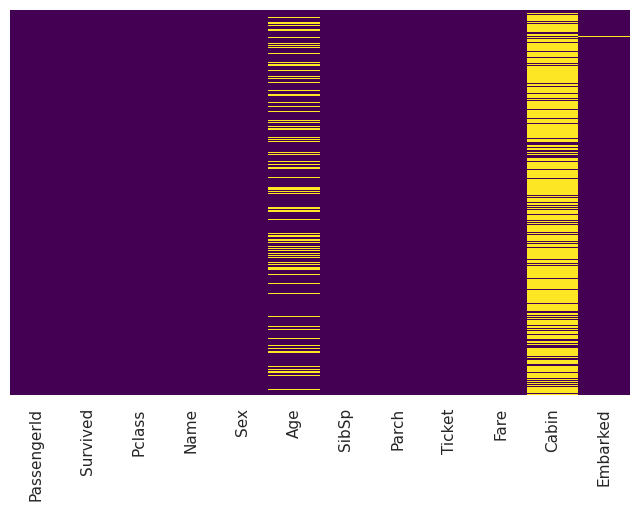

In [158]:
# 2. Dibuja el mapa de calor de df.isnull():
#    sns.heatmap(..., cbar=False, yticklabels=False, cmap='viridis')
sns.heatmap(df.isnull(), cbar=False, yticklabels=False, cmap='viridis')

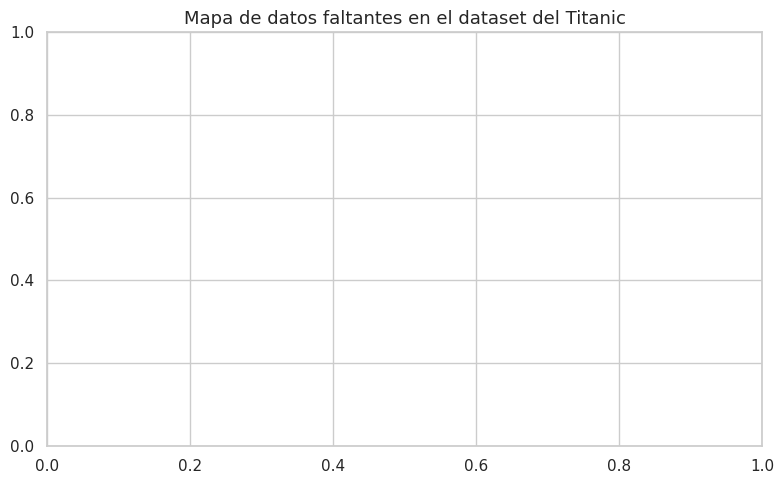

In [159]:
# 3. Añade un título con plt.title(...) y cierra con plt.show().
plt.title('Mapa de datos faltantes en el dataset del Titanic')
plt.tight_layout()
plt.show()


### Evaluación — Parte 1

- **E1.1 (conceptual).** ¿Cuántos pasajeros hay en total? ¿Qué columnas son numéricas y cuáles categóricas? Atención: `Survived` y `Pclass` aparecen como números, pero ¿se comportan como números (¿tiene sentido promediar `Pclass`?)


**R//** Hay 891 pasajeros en total. Son numéricas continuas o de conteo variables como Age, Fare, SibSp y Parch; son categóricas o identificadores Sex, Embarked, Name, Ticket y Cabin. Aunque Survived (binaria 0/1) y Pclass (ordinal 1, 2, 3) vienen como números, son categóricas: promediar Pclass no tiene sentido físico directo como un valor continuo, aunque a veces se use como referencia descriptiva.

- **E1.2 (conceptual).** ¿Qué problemas "obvios" observas en los datos (columnas inútiles para el análisis, tipos extraños, faltantes)?


**R//** Se observan muchos datos faltantes en Cabin (y varios en Age, además de pocos en Embarked), columnas identificadoras o de texto libre (PassengerId, Name, Ticket) que requieren extracción de patrones (como títulos en Name) más que uso directo, y variables codificadas como números (Survived, Pclass) que deben tratarse como categorías.

- **E1.3 (código).** Calcula el **porcentaje** de datos faltantes por columna, ordenado de mayor a menor.


In [160]:
# Reto E1.3 — Pista: isnull().mean() devuelve la proporción de nulos por columna;
# multiplica por 100, redondea con round(1) y ordena con sort_values(ascending=False).

(df.isnull().mean() * 100).round(1).sort_values(ascending=False)


,0
Cabin,77.1
Age,19.9
Embarked,0.2
PassengerId,0.0
Name,0.0
Pclass,0.0
Survived,0.0
Sex,0.0
Parch,0.0
SibSp,0.0


- **E1.4 (conceptual).** ¿Qué columnas tienen más datos faltantes? ¿Podrían sesgar el análisis? Piensa: ¿los faltantes parecen "al azar" o tienen una causa?


**R//** Las columnas con más datos faltantes son Cabin (la gran mayoría vacía) y Age (varios faltantes), además de pocos nulos en Embarked. Sí pueden sesgar el análisis: no suelen faltar puramente al azar, sino por cómo se registraron los datos (por ejemplo, Cabin se anotaba más en pasajeros con camarote asignado/clases altas o no se recuperó para muchos pasajeros, y Age faltó en registros incompletos), lo que afecta estimaciones por clase o edad.

- **E1.5 (conceptual — reflexión).** ¿Por qué usamos varias bibliotecas en lugar de una sola? Da un ejemplo de tarea para cada una.


**R//** Cada librería está especializada para ser más clara, rápida o expresiva en su tarea: Pandas manipula tablas y agrupaciones (df.groupby), NumPy hace cálculos vectorizados rápidos (np.where), Matplotlib controla detalles de figuras y ejes (plt.title), Seaborn crea gráficos estadísticos con facilidad (sns.countplot) y SciPy aplica pruebas estadísticas (stats).   

## Parte 2 — Conociendo a los pasajeros (Pasos 6–10)

> **Teoría — dos herramientas nuevas.**
> - `sns.countplot(data=df, x='col', hue='otra')` cuenta filas por categoría; `hue` divide cada barra por una segunda variable.
> - `pd.crosstab(a, b)` produce la **tabla cruzada** (conteos de cada combinación). Con `normalize='columns'` (o `'index'`) los conteos pasan a **proporciones** que suman 1 por columna (o por fila).
>
> Para **comparar grupos de distinto tamaño** usa proporciones, no conteos absolutos.


### Paso 6. Distribución por género y su cruce con la clase


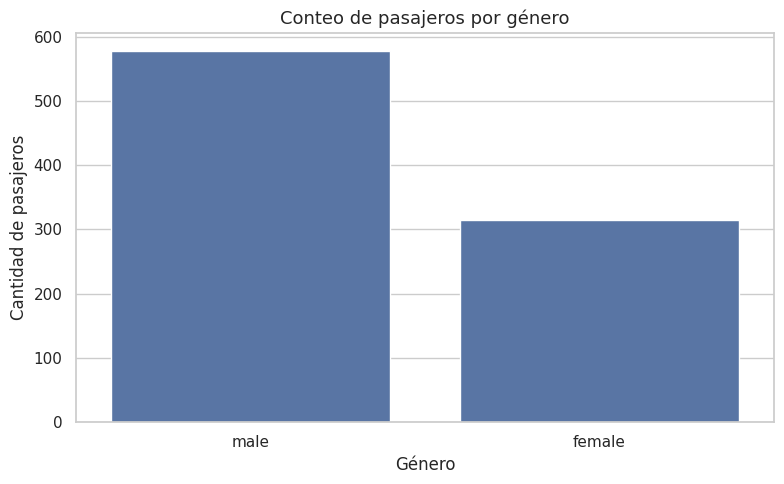

In [161]:
# 1. Gráfico de conteo de 'Sex'.
sns.countplot(data=df, x='Sex')
plt.title('Conteo de pasajeros por género')
plt.xlabel('Género')
plt.ylabel('Cantidad de pasajeros')
plt.tight_layout()
plt.show()

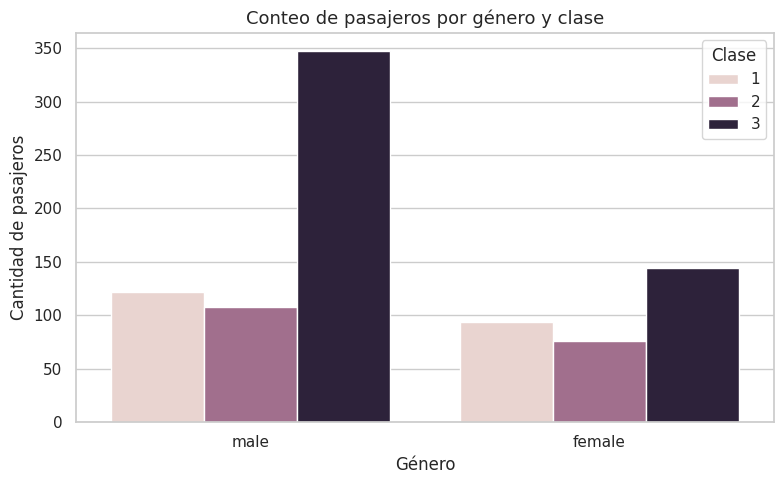

In [162]:
# 2. Gráfico de conteo de 'Sex' con hue='Pclass'.
sns.countplot(data=df, x='Sex', hue='Pclass')
plt.title('Conteo de pasajeros por género y clase')
plt.xlabel('Género')
plt.ylabel('Cantidad de pasajeros')
plt.legend(title='Clase')
plt.tight_layout()
plt.show()

In [163]:
# 3. Tabla cruzada Sex x Pclass NORMALIZADA POR COLUMNAS:
#    ¿qué proporción de cada clase son mujeres?
pd.crosstab(df['Sex'], df['Pclass'], normalize='columns')

Pclass,1,2,3
Sex,,,
female,0.435185,0.413043,0.293279
male,0.564815,0.586957,0.706721


### Paso 7. Distribución de edades

**Lógica:** un **histograma** divide la variable numérica en intervalos (*bins*) y cuenta cuántos casos caen en cada uno. `Age` tiene nulos: Seaborn los ignora al graficar, pero es bueno hacerlo explícito con `dropna()`.


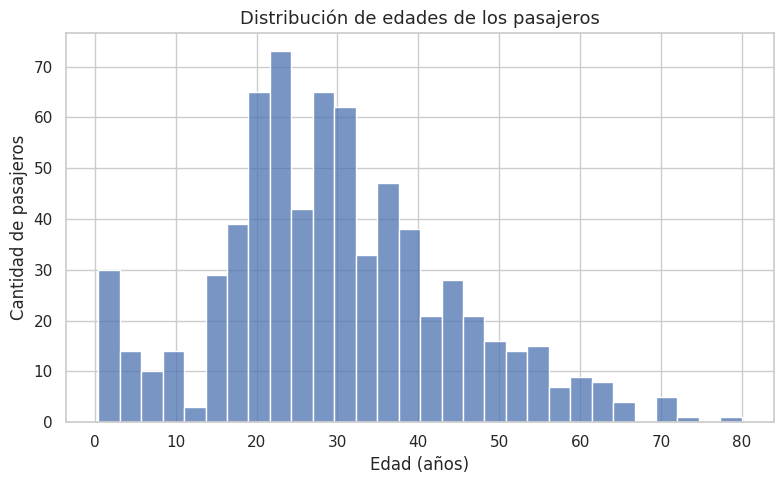

In [164]:
# 1. Histograma de la edad: sns.histplot(df['Age'].dropna(), bins=30)
#    Añade título y etiquetas de los ejes.
sns.histplot(df['Age'].dropna(), bins=30)
plt.title('Distribución de edades de los pasajeros')
plt.xlabel('Edad (años)')
plt.ylabel('Cantidad de pasajeros')
plt.tight_layout()
plt.show()

In [165]:
# 2. Calcula la edad promedio (Pandas ignora los NaN automáticamente).
df['Age'].mean()

np.float64(29.69911764705882)

In [166]:
# 3. Explora: mediana, mínimo y máximo de la edad.

print("Mediana:", df['Age'].median())
print("Mínimo:", df['Age'].min())
print("Máximo:", df['Age'].max())

Mediana: 28.0
Mínimo: 0.42
Máximo: 80.0


### Paso 8. Crear la variable `Person` (hombre, mujer o niño)

**Lógica:** `np.where(condición, valor_si_True, valor_si_False)` crea una columna de forma **vectorizada** (sin `for`). Aquí: si `Age < 16` → `'child'`; si no, se conserva el valor de `Sex`.


In [167]:
# Crea df['Person'] con np.where:
#   condición: df['Age'] < 16
#   si True: 'child'      si False: df['Sex']
df['Person'] = np.where(df['Age'] < 16, 'child', df['Sex'])

In [168]:
# Luego cuenta cuántos hay de cada tipo con value_counts().
df['Person'].value_counts()

,count
Person,
male,537
female,271
child,83


> **Advertencia — los NaN y las comparaciones.** En Pandas/NumPy, `NaN < 16` da `False`. Por lo tanto, **un pasajero sin edad nunca será `child`**: se queda con su sexo. Es un sesgo silencioso. Lo investigarás en E2.5.


### Paso 9. ¿Cuántos niños viajaban en cada clase?


In [169]:
# Tabla cruzada de 'Pclass' (filas) contra 'Person' (columnas).
pd.crosstab(df['Pclass'], df['Person'])

Person,child,female,male
Pclass,,,
1,6,91,119
2,19,66,99
3,58,114,319


### Paso 10. Gráficos de densidad (KDE) de la edad

> **Teoría — KDE.** La *estimación de densidad por kernel* es un "histograma suavizado": la curva muestra dónde se concentran los valores. Con `hue` se superponen varias curvas. Usa `common_norm=False` para que **cada grupo se normalice por separado** (si no, los grupos grandes "aplastan" a los pequeños).



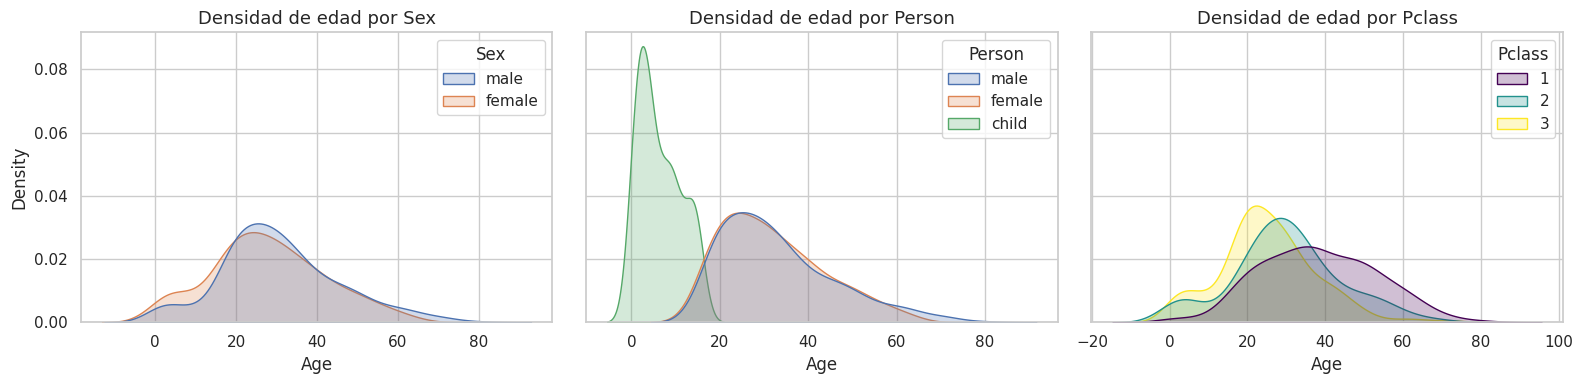

In [170]:
# Crea una figura de 1 fila x 3 columnas: fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
# Dibuja en cada eje (parámetro ax=axes[i]) un sns.kdeplot(data=df, x='Age', hue=..., fill=True, common_norm=False):
#   axes[0] -> hue='Sex'
#   axes[1] -> hue='Person'
#   axes[2] -> hue='Pclass'   (añade palette='viridis')
sns.kdeplot(data=df, x='Age', hue='Sex', fill=True, common_norm=False, ax=axes[0])
sns.kdeplot(data=df, x='Age', hue='Person', fill=True, common_norm=False, ax=axes[1])
sns.kdeplot(data=df, x='Age', hue='Pclass', fill=True, common_norm=False, palette='viridis', ax=axes[2])

# Ponle un título a cada eje con axes[i].set_title(...) y cierra con plt.tight_layout(); plt.show()
axes[0].set_title('Densidad de edad por Sex')
axes[1].set_title('Densidad de edad por Person')
axes[2].set_title('Densidad de edad por Pclass')
plt.tight_layout()
plt.show()

### Evaluación — Parte 2


- **E2.1 (conceptual).** ¿Hay diferencias en la composición de género entre clases? Apóyate en la tabla normalizada del Paso 6.


**R//** Sí hay diferencias en la composición por género entre clases: según la tabla cruzada normalizada por columnas del Paso 6, la proporción de mujeres (female) suele ser mayor en 1.ª clase que en 3.ª clase, donde predominan más los hombres (male).   

- **E2.2 (código).** Calcula la proporción de menores de 16 años en cada clase (no el conteo).


In [171]:
# Retos E2.2 -> (df['Age'] < 16).groupby(df['Pclass']).mean()
(df['Age'] < 16).groupby(df['Pclass']).mean()

,Age
Pclass,
1,0.027778
2,0.103261
3,0.118126


- **E2.3 (conceptual).** Describe la distribución de edades del Titanic. ¿Cómo era el pasajero "típico"?


**R//** La distribución de edades se concentra principalmente en adultos jóvenes y de mediana edad (alrededor de los 20 a 35 años), con presencia de niños y personas mayores; el pasajero "típico" rondaba esa franja adulta joven (alrededor de la media/mediana observada en el Paso 7).   

- **E2.4 (conceptual).** Según los KDE por clase, ¿qué clase tiene pasajeros de más edad? Propón una explicación social (no estadística) para esa diferencia.


**R//** En los KDE por clase, la 1.ª clase tiende a concentrar pasajeros de mayor edad que la 3.ª clase. Una explicación social es que alcanzar mayor posición económica o patrimonio para costear camarotes de primera clase tomaba más años de trayectoria laboral y vital, mientras que en 3.ª clase viajaban más jóvenes y familias migrantes buscando oportunidades.   

- **E2.5 (código + conceptual).** ¿Cuántos pasajeros **sin edad** quedaron clasificados como `male` o `female` en `Person`? ¿Por qué eso puede subestimar el número de niños?


In [172]:
# Retos E2.5-> filtra df[df['Age'].isnull()] y cuenta sus valores de 'Person'
df[df['Age'].isnull()]['Person'].value_counts()

,count
Person,
male,124
female,53


**R//** Todos los pasajeros con Age nulo quedaron clasificados como male o female porque NaN < 16 resulta False en np.where. Esto subestima el conteo de child porque algunos menores sin edad registrada no fueron identificados como niños.

## Parte 3 — Ubicación, embarque y composición familiar (Pasos 11–15)

> **Teoría — extraer información de texto.** Con una Serie de texto, el accesor `.str` aplica operaciones a cada elemento a la vez: `serie.str[0]` toma el primer carácter. En `Cabin` (por ejemplo `'C85'`) la primera letra indica la **cubierta**.



### Paso 11. Extraer la cubierta de la cabina


In [173]:
# 1. Guarda en 'cabinas' las cabinas NO nulas: df['Cabin'].dropna()
cabinas = df['Cabin'].dropna()

In [174]:
# 2. Crea 'cubierta' tomando la primera letra de cada cabina (.str[0]).
cubierta = cabinas.str[0]

In [175]:
# 3. Muestra los conteos por cubierta con value_counts().
#    NO modifiques df todavía: lo haremos en la Parte 5.
cubierta.value_counts()

,count
Cabin,
C,59
B,47
D,33
E,32
A,15
F,13
G,4
T,1


### Paso 12. Gráfico de conteo por cubierta (con depuración de anómalos)


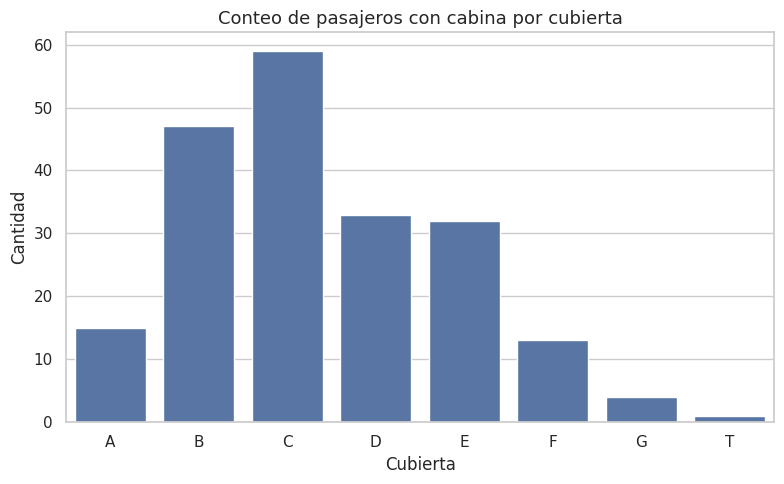

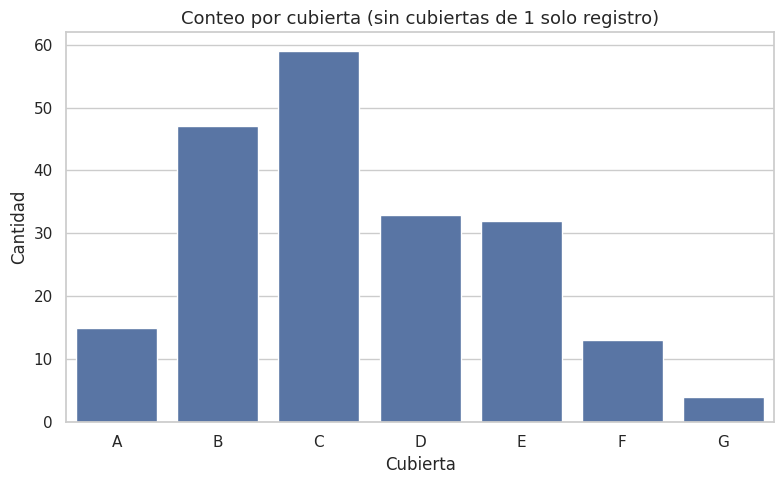

In [176]:
# 1. Dibuja sns.countplot(x=cubierta, order=sorted(cubierta.unique())) con título y etiquetas.
sns.countplot(x=cubierta, order=sorted(cubierta.unique()))
plt.title('Conteo de pasajeros con cabina por cubierta')
plt.xlabel('Cubierta')
plt.ylabel('Cantidad')
plt.tight_layout()
plt.show()
# 2. Si encuentras una cubierta con un solo registro (anómala), elimínala de 'cubierta'
#    (cubierta = cubierta[cubierta != '?']) y vuelve a graficar.

conteos_cub = cubierta.value_counts()
anomalas = conteos_cub[conteos_cub == 1].index
for letra in anomalas:
    cubierta = cubierta[cubierta != letra]

sns.countplot(x=cubierta, order=sorted(cubierta.unique()))
plt.title('Conteo por cubierta (sin cubiertas de 1 solo registro)')
plt.xlabel('Cubierta')
plt.ylabel('Cantidad')
plt.tight_layout()
plt.show()


### Paso 13. Puerto de embarque y clase


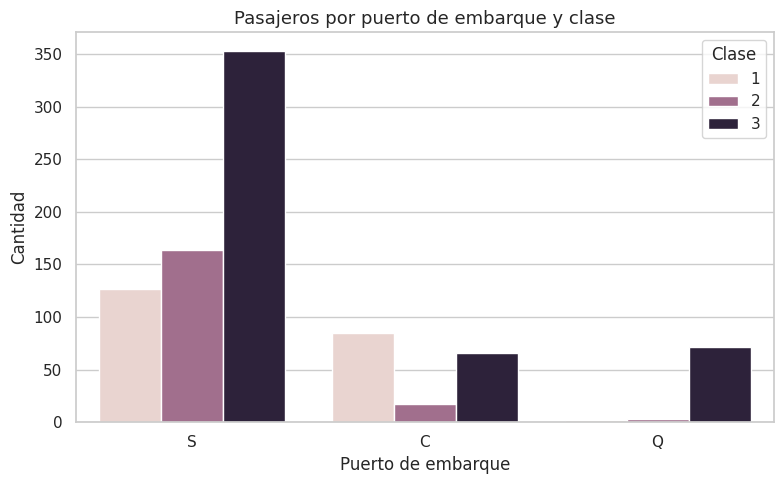

Pclass,1,2,3
Embarked,,,
C,0.505952,0.101190,0.392857
Q,0.025974,0.038961,0.935065
S,0.197205,0.254658,0.548137


In [177]:
# 1. Gráfico de conteo de 'Embarked' con hue='Pclass'.
sns.countplot(data=df, x='Embarked', hue='Pclass')
plt.title('Pasajeros por puerto de embarque y clase')
plt.xlabel('Puerto de embarque')
plt.ylabel('Cantidad')
plt.legend(title='Clase')
plt.tight_layout()
plt.show()
# 2. Tabla cruzada Embarked x Pclass normalizada por FILAS (normalize='index'):
#    ¿qué composición de clases tiene cada puerto?

pd.crosstab(df['Embarked'], df['Pclass'], normalize='index')

### Paso 14. Crear la variable `Alone` (solo vs. con familia)

**Lógica:** `SibSp + Parch` es el número de familiares a bordo. Si es 0, viaja solo.


In [178]:
# 1. Crea df['Familia'] = df['SibSp'] + df['Parch']
df['Familia'] = df['SibSp'] + df['Parch']

In [179]:
# 2. Crea df['Alone'] con np.where: 'with Family' si Familia > 0, 'Alone' si no.
df['Alone'] = np.where(df['Familia'] > 0, 'With Family', 'Alone')

In [180]:
# 3. Calcula la proporción de cada categoría con value_counts(normalize=True).
df['Alone'].value_counts(normalize=True)

,proportion
Alone,
Alone,0.602694
With Family,0.397306


### Paso 15. Visualizar la distribución de `Alone`


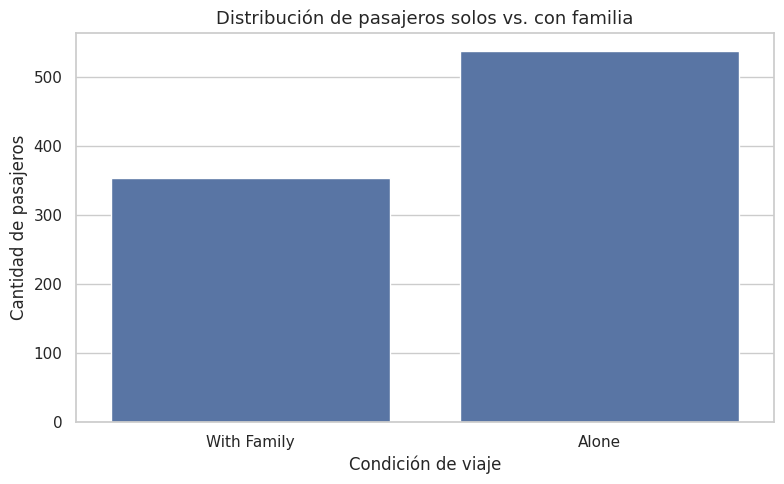

In [181]:
# Gráfico de conteo de 'Alone' (con título y etiquetas).
sns.countplot(data=df, x='Alone')
plt.title('Distribución de pasajeros solos vs. con familia')
plt.xlabel('Condición de viaje')
plt.ylabel('Cantidad de pasajeros')
plt.tight_layout()
plt.show()

### Evaluación — Parte 3


- **E3.1 (código).** ¿Qué porcentaje de pasajeros tiene información de cabina?


In [182]:
# Reto E3.1 — Pista: df['Cabin'].notna().mean() * 100
df['Cabin'].notna().mean() * 100

np.float64(22.895622895622896)

- **E3.2 (conceptual).** ¿Qué cubiertas eran las más ocupadas? ¿Qué implicaciones tiene que falten tantos datos de cabina? ¿Esa "ocupación" refleja de verdad el barco?


**R//** Las cubiertas con más registros en los datos son C, B y D. Sin embargo, esa "ocupación" no refleja la distribución real del barco, ya que casi el 80 % de los pasajeros no tiene cabina registrada y los datos disponibles corresponden principalmente a pasajeros de 1.ª clase, sesgando el conteo hacia las cubiertas superiores.

- **E3.3 (conceptual).** En el Paso 12, ¿era correcto eliminar la cubierta anómala? Da un argumento a favor y uno en contra.


**R//** A favor: eliminar el único registro (T) limpia el gráfico de una categoría sin muestra representativa que no permite comparar patrones. En contra: se pierde un dato histórico real (la cubierta tanque/superior existía) y se altera el registro original antes de investigar si era un caso válido.

- **E3.4 (conceptual).** ¿Existe relación entre el puerto de embarque y la clase? Describe qué puerto se parece más a "tercera clase" y cuál a "primera".


**R//** Sí existe relación entre el puerto de embarque y la clase. Según la tabla normalizada por filas del Paso 13, Queenstown (Q) se parece más a "tercera clase" (casi todos sus pasajeros viajaban en 3.ª), mientras que Cherbourg (C) se parece más a "primera clase" (tiene la mayor proporción de pasajeros de 1.ª clase), y Southampton (S) concentra la mayor cantidad absoluta con mayoría de 3.ª clase.

- **E3.5 (conceptual).** ¿Qué proporción viajaba sola? Formula una **hipótesis** (con su razón) sobre si viajar en familia afectó la supervivencia. La verificarás en la Parte 9.


**R//** Alrededor del 60 % viajaba solo (Alone) y el 40 % con familia (With Family). Hipótesis: viajar en familia pudo aumentar la supervivencia en familias pequeñas porque se ayudaban mutuamente y tenían prioridad en la evacuación de mujeres y niños, aunque familias muy numerosas pudieron tener mayor dificultad para mantenerse juntas y abordar los botes a tiempo.

## Parte 4 — Análisis de supervivencia: el núcleo del taller (Pasos 16–20)

> **Teoría — la media de una variable 0/1 es una proporción.** Si `Survived` vale 1 para quien sobrevivió y 0 para quien no, entonces `df['Survived'].mean()` es la **tasa de supervivencia**. Por eso los gráficos de Seaborn que promedian (`catplot` tipo punto, `lmplot`) usan la columna **numérica** `Survived` en el eje y; la columna de texto `Survivor` sirve para etiquetar gráficos de conteo.
>
> **Las barritas verticales** de los gráficos de puntos son **intervalos de confianza al 95 %**: indican la *incertidumbre*. Barras largas = pocos datos o mucha variabilidad.



### Paso 16. Panorama general


In [183]:
# 1. Crea df['Survivor'] mapeando 0 -> 'No' y 1 -> 'Yes' con .map({...}).
df['Survivor'] = df['Survived'].map({0: 'No', 1: 'Yes'})

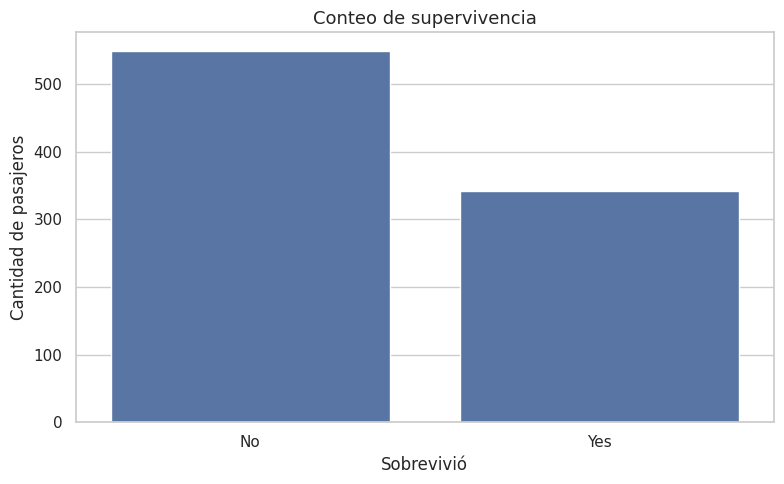

In [184]:
# 2. Gráfico de conteo de 'Survivor'.
sns.countplot(data=df, x='Survivor')
plt.title('Conteo de supervivencia')
plt.xlabel('Sobrevivió')
plt.ylabel('Cantidad de pasajeros')
plt.tight_layout()
plt.show()

In [185]:
# 3. Calcula la tasa general de supervivencia (media de 'Survived').
df['Survived'].mean()

np.float64(0.3838383838383838)

### Paso 17. Supervivencia por clase


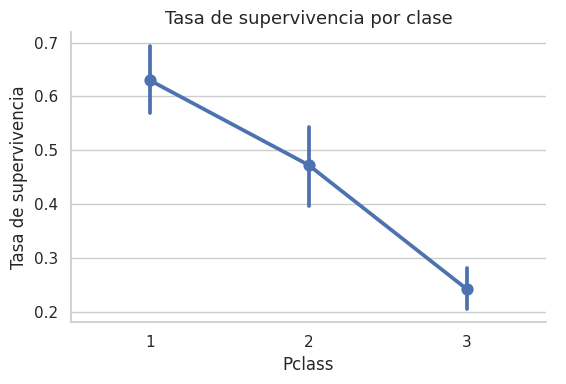

In [186]:
# Gráfico de puntos: sns.catplot(data=df, x='Pclass', y='Survived', kind='point', height=4, aspect=1.4)
# Añade título con plt.title(...) y etiqueta del eje y: "Tasa de supervivencia".
sns.catplot(data=df, x='Pclass', y='Survived', kind='point', height=4, aspect=1.4)
plt.title('Tasa de supervivencia por clase')
plt.ylabel('Tasa de supervivencia')
plt.tight_layout()
plt.show()

### Paso 18. Supervivencia por clase y tipo de persona


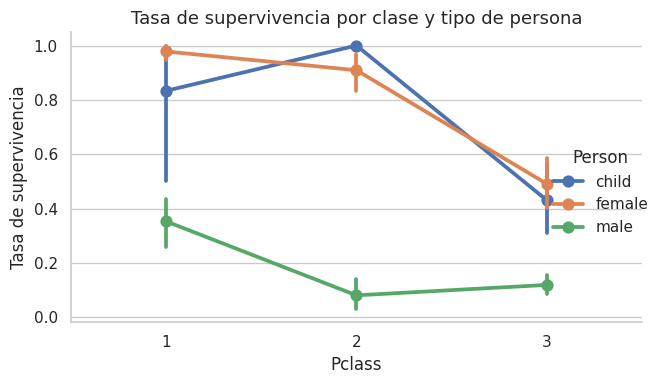

In [187]:
# Repite el gráfico anterior añadiendo hue='Person' y hue_order=['child', 'female', 'male'].
sns.catplot(
    data=df,
    x='Pclass',
    y='Survived',
    hue='Person',
    hue_order=['child', 'female', 'male'],
    kind='point',
    height=4,
    aspect=1.4
)
plt.title('Tasa de supervivencia por clase y tipo de persona')
plt.ylabel('Tasa de supervivencia')
plt.tight_layout()
plt.show()

### Paso 19. Edad y supervivencia

> **Teoría — `lmplot`.** Dibuja una **recta de regresión** (con banda de confianza) de y contra x. Con `y` binaria (0/1) la recta es solo una *aproximación visual* de la tendencia. El parámetro `x_bins` agrupa la edad en intervalos y dibuja la **tasa media por intervalo**, lo cual es mucho más legible.


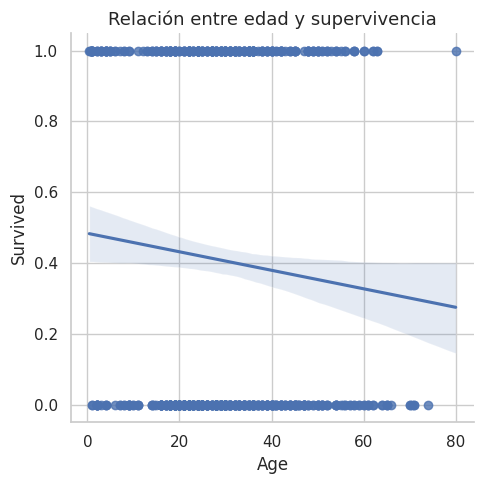

In [188]:
# 1. sns.lmplot(data=df, x='Age', y='Survived')
sns.lmplot(data=df, x='Age', y='Survived')
plt.title('Relación entre edad y supervivencia')
plt.tight_layout()
plt.show()

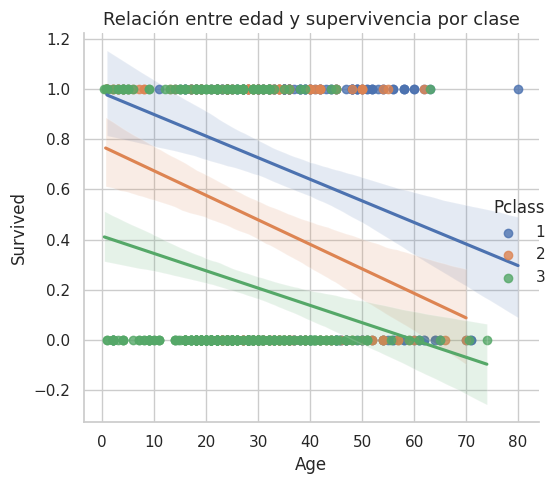

In [189]:
# 2. Añade hue='Pclass'.
sns.lmplot(data=df, x='Age', y='Survived', hue='Pclass')
plt.title('Relación entre edad y supervivencia por clase')
plt.tight_layout()
plt.show()

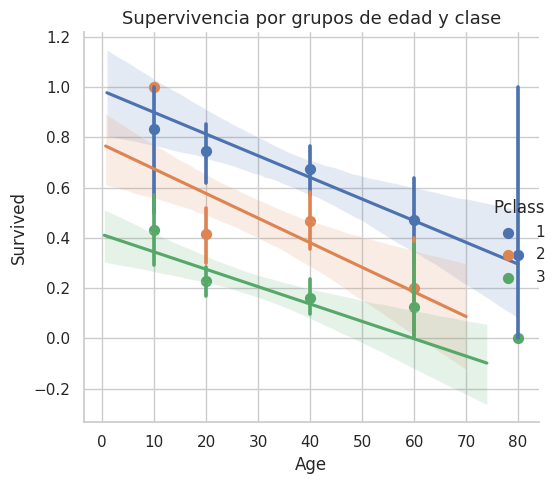

In [190]:
# 3. Define generaciones = [10, 20, 40, 60, 80] y usa x_bins=generaciones con hue='Pclass'.
generaciones = [10, 20, 40, 60, 80]
sns.lmplot(data=df, x='Age', y='Survived', hue='Pclass', x_bins=generaciones)
plt.title('Supervivencia por grupos de edad y clase')
plt.tight_layout()
plt.show()

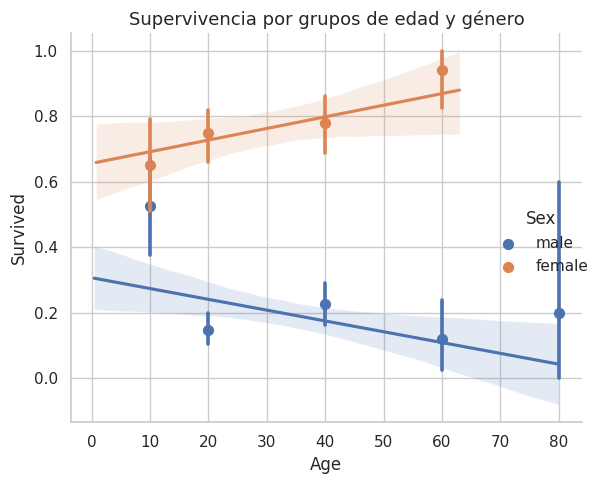

In [191]:
# 4. Repite el punto 3 con hue='Sex'.
sns.lmplot(data=df, x='Age', y='Survived', hue='Sex', x_bins=generaciones)
plt.title('Supervivencia por grupos de edad y género')
plt.tight_layout()
plt.show()

### Paso 20. Relación tarifa-edad


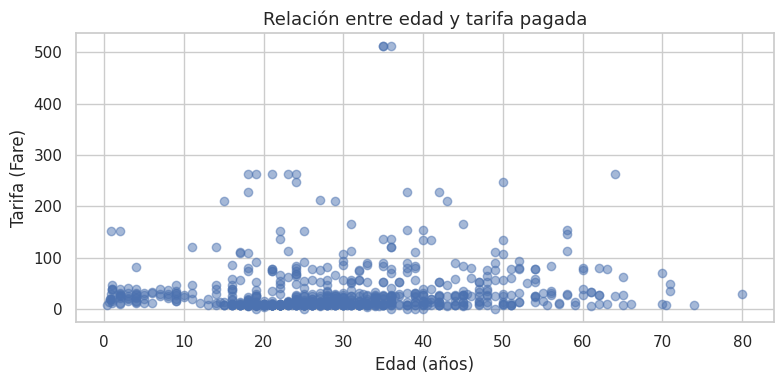

In [192]:
# 1. Dispersión simple: plt.scatter(df['Age'], df['Fare'], alpha=0.5)
plt.figure(figsize=(8, 4))
plt.scatter(df['Age'], df['Fare'], alpha=0.5)
plt.title('Relación entre edad y tarifa pagada')
plt.xlabel('Edad (años)')
plt.ylabel('Tarifa (Fare)')
plt.tight_layout()
plt.show()

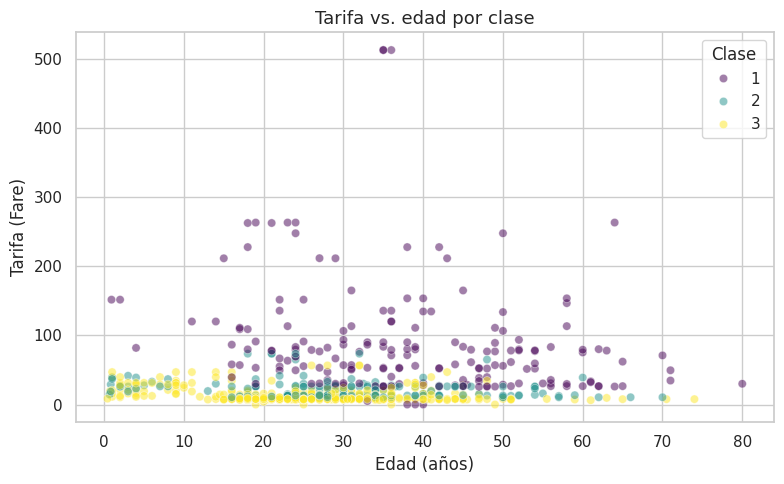

In [193]:
# 2. Desafío: sns.scatterplot(data=df, x='Age', y='Fare', hue='Pclass', alpha=0.5, palette='viridis')
# Añade título y etiquetas.
sns.scatterplot(data=df, x='Age', y='Fare', hue='Pclass', alpha=0.5, palette='viridis')
plt.title('Tarifa vs. edad por clase')
plt.xlabel('Edad (años)')
plt.ylabel('Tarifa (Fare)')
plt.legend(title='Clase')
plt.tight_layout()
plt.show()

### Evaluación — Parte 4


- **E4.1 (conceptual).** ¿Cuál fue la tasa general de supervivencia? ¿Qué clase tuvo mejor tasa y por qué crees que ocurrió?


**R//**  La tasa general de supervivencia fue aproximadamente del 38.4 % (0.3838). La 1.ª clase tuvo la mejor tasa (63 %), seguida de 2.ª (47 %) y 3.ª (24 %). Esto ocurrió porque los camarotes de primera estaban más cerca de las cubiertas de botes salvavidas, recibieron información y acceso más rápido durante la evacuación y tuvieron mayor prioridad social.

- **E4.2 (código).** Construye una **tabla** con la tasa de supervivencia por `Pclass` (filas) y `Person` (columnas). ¿Se cumplió "mujeres y niños primero"? ¿Hay excepciones?


In [194]:
# Reto E4.2 — Pista: df.pivot_table(values='Survived', index='Pclass', columns='Person', aggfunc='mean')
df.pivot_table(values='Survived', index='Pclass', columns='Person', aggfunc='mean')

Person,child,female,male
Pclass,,,
1,0.833333,0.978022,0.352941
2,1.000000,0.909091,0.080808
3,0.431034,0.491228,0.119122


In [195]:
# Reto extra: añade aggfunc=['mean', 'count'] para ver también el tamaño de cada grupo.
df.pivot_table(values='Survived', index='Pclass', columns='Person', aggfunc=['mean', 'count'])

mean                     count            
Person     child    female      male child female male
Pclass                                                
1       0.833333  0.978022  0.352941     6     91  119
2       1.000000  0.909091  0.080808    19     66   99
3       0.431034  0.491228  0.119122    58    114  319

**R//** *(En general sí se cumplió "mujeres y niños primero" en 1.ª y 2.ª clase con tasas muy altas, pero con excepción clara en *3.ª clase**, donde tanto mujeres como niños tuvieron tasas de supervivencia mucho menores alrededor del 43–49 %).*

- **E4.3 (conceptual).** ¿Era ser hombre en tercera clase particularmente peligroso? ¿Los niños recibieron el mismo trato en todas las clases?


**R//** Sí, ser hombre adulto en 3.ª clase fue particularmente peligroso (apenas alrededor del 12 % sobrevivió). No, los niños no recibieron el mismo trato efectivo en todas las clases: en 1.ª y 2.ª clase sobrevivió casi la totalidad (especialmente en 2.ª), mientras que en 3.ª clase sobrevivió menos de la mitad debido a las barreras físicas de acceso a cubierta y la distancia desde los niveles inferiores.

- **E4.4 (conceptual).** En el Paso 19, ¿existe una tendencia entre edad y supervivencia? ¿Cambia por clase? ¿Y por género? ¿Qué cambia al variar los *bins*?


**R//**  En general existe una ligera tendencia negativa (a mayor edad, menor supervivencia promedio), pero cambia mucho según el grupo: al separar por Pclass las curvas de 1.ª clase se mantienen más altas que las de 3.ª, y al separar por Sex las mujeres mantienen tasas altas en casi todas las edades mientras los hombres tienen tasas bajas salvo en niños. Al usar x_bins, la recta continua se reemplaza por promedios discretos por rango de edad, mostrando mejor saltos no lineales (como el pico infantil).

- **E4.5 (conceptual).** En el Paso 18, el intervalo de confianza de los niños de primera clase es muy ancho. ¿Por qué? ¿Qué cuidado implica para interpretar ese punto?


**R//** El intervalo de confianza de los niños de 1.ª clase es muy ancho porque había muy pocos niños en primera clase (muestra diminuta, alrededor de 6 registros). Esto implica cautela al interpretar ese punto: aunque su tasa observada sea alta, la incertidumbre estadística es grande y un solo caso cambiaría mucho el porcentaje.

- **E4.6 (conceptual).** ¿Qué revela el gráfico tarifa-edad coloreado por clase sobre la relación entre tarifa, edad y clase?


**R//**  El gráfico revela que la tarifa está fuertemente determinada por la clase (Pclass) y no por la edad: en todas las edades los puntos de 1.ª clase se ubican en las tarifas más altas (incluyendo valores extremos por encima de 200–500), mientras que 2.ª y 3.ª clase permanecen concentradas en tarifas bajas a lo largo de todo el rango de edad.

## Parte 5 — Limpieza y preparación de datos (Pasos 21–26)

> **Teoría — tres decisiones de limpieza.** Un dato faltante puede (a) eliminarse, (b) rellenarse con un valor "razonable" (*imputación*) o (c) conservarse como una categoría propia ("desconocido"). **Ninguna opción es neutral:** cada una cambia lo que los datos dicen. Documenta siempre qué hiciste y por qué.
>
> **Teoría — codificación.** Los modelos y las correlaciones necesitan números. Convertir categorías a números con `.map({...})` crea columnas nuevas (con prefijo `N`). Cuidado: **un número impone un orden** que quizá no existe (¿es "Q = 2" mayor que "S = 0"?).


### Paso 21. Datos faltantes en `Embarked`


In [196]:
# 1. ¿Cuántos valores faltan en 'Embarked'?
df['Embarked'].isnull().sum()

np.int64(2)

In [197]:
# 2. Calcula la categoría más frecuente: df['Embarked'].mode()[0]
moda_embarked = df['Embarked'].mode()[0]
moda_embarked

'S'

In [198]:
# 3. Rellena los faltantes con esa moda usando fillna (asigna el resultado a la columna;
#    evita inplace=True).
df['Embarked'] = df['Embarked'].fillna(moda_embarked)

In [199]:
# 4. Crea df['NEmbarked'] mapeando S -> 0, C -> 1, Q -> 2.
df['NEmbarked'] = df['Embarked'].map({'S': 0, 'C': 1, 'Q': 2})

### Paso 22. Datos faltantes en `Age`

**Lógica:** en lugar de rellenar con el promedio global, rellenamos con el **promedio de su grupo** (género). Se calcula una tabla `promedio por género` y se "traduce" cada pasajero a su promedio con `.map`.


In [200]:
# 1. Calcula la edad promedio por género: df.groupby('Sex')['Age'].mean()
promedios = df.groupby('Sex')['Age'].mean()
promedios

,Age
Sex,
female,27.915709
male,30.726645


In [201]:
# 2. Rellena los nulos de 'Age': df['Age'] = df['Age'].fillna(df['Sex'].map(promedios))
std_age_antes = df['Age'].std()
df['Age'] = df['Age'].fillna(df['Sex'].map(promedios))

In [202]:
# 3. Verifica que no queden nulos en 'Age'.
df['Age'].isnull().sum()

np.int64(0)

In [203]:
# 4. Guarda la desviación estándar de 'Age' ANTES de rellenar para compararla en E5.3.
print("Desviación estándar ANTES de rellenar:", std_age_antes)
print("Desviación estándar DESPUÉS de rellenar:", df['Age'].std())

Desviación estándar ANTES de rellenar: 14.526497332334044
Desviación estándar DESPUÉS de rellenar: 13.01489687938195


### Paso 23. Convertir `Sex` a número


In [204]:
# Crea df['NSex'] mapeando female -> 0 y male -> 1.
df['NSex'] = df['Sex'].map({'female': 0, 'male': 1})

### Paso 24. Tratamiento de `Cabin`


In [205]:
# 1. Rellena los nulos de 'Cabin' con 'X' (desconocido).
df['Cabin'] = df['Cabin'].fillna('X')

In [206]:
# 2. Crea df['TCabin'] con la primera letra de la cabina.
df['TCabin'] = df['Cabin'].str[0]

In [207]:
# 3. Cuenta los pasajeros por cubierta (value_counts).
df['TCabin'].value_counts()

,count
TCabin,
X,687
C,59
B,47
D,33
E,32
A,15
F,13
G,4
T,1


In [208]:
# 4. Crea df['NCabin'] asignando un número a cada cubierta:
#    mapa = {letra: i for i, letra in enumerate(sorted(df['TCabin'].unique()))}
mapa = {letra: i for i, letra in enumerate(sorted(df['TCabin'].unique()))}
df['NCabin'] = df['TCabin'].map(mapa)

### Paso 25. Extracción de títulos del nombre

> **Teoría — expresiones regulares (regex).** Los nombres tienen la forma `"Braund, Mr. Owen Harris"`. El título está entre la coma y el punto. El patrón `r',\s*([^.]+)\.'` significa: una coma, espacios opcionales (`\s*`), y captura (`( )`) todo lo que no sea un punto (`[^.]+`), hasta el punto. `str.extract(patron, expand=False)` devuelve la parte capturada.


In [209]:
# 1. Crea df['TTitulo'] = df['Name'].str.extract(r',\s*([^.]+)\.', expand=False).str.strip()
df['Titulo'] = df['Name'].str.extract(r',\s*([^\.]+)\.', expand=False).str.strip()

In [210]:
# 2. Analiza la frecuencia de cada título (value_counts).
df['Titulo'].value_counts()

,count
Titulo,
Mr,517
Miss,182
Mrs,125
Master,40
Dr,7
Rev,6
Col,2
Mlle,2
Major,2


In [211]:
# 3. Tabla cruzada de título vs. género (pd.crosstab(df['TTitulo'], df['Sex'])).
pd.crosstab(df['Titulo'], df['Sex'])

Sex,female,male
Titulo,,
Capt,0,1
Col,0,2
Don,0,1
Dr,1,6
Jonkheer,0,1
Lady,1,0
Major,0,2
Master,0,40
Miss,182,0


### Paso 26. Consolidar títulos

**Lógica:** los títulos raros dejan grupos de 1 o 2 personas: inútiles para estadística. Se agrupan en categorías más generales con `replace` (un diccionario) y `where/isin` (todo lo que no esté en la lista principal pasa a `'Otro'`).



In [212]:
# 1. Reemplaza con un diccionario:
#      Master -> Mr ;  the Countess, Dona, Mme -> Mrs ;  Lady, Mlle, Ms -> Miss
reemplazos = {
    'Master': 'Mr',
    'the Countess': 'Mrs',
    'Dona': 'Mrs',
    'Mme': 'Mrs',
    'Lady': 'Miss',
    'Mlle': 'Miss',
    'Ms': 'Miss'
}
df['Titulo'] = df['Titulo'].replace(reemplazos)

In [213]:
# 2. Todo título que NO esté en ['Mr', 'Mrs', 'Miss'] debe pasar a 'Otro'.
#    Pista: df['TTitulo'].where(df['TTitulo'].isin([...]), 'Otro')
df['Titulo'] = df['Titulo'].where(df['Titulo'].isin(['Mr', 'Mrs', 'Miss']), 'Otro')

In [214]:
# 3. Revisa los conteos finales.
df['Titulo'].value_counts()

,count
Titulo,
Mr,557
Miss,186
Mrs,127
Otro,21


In [215]:
# 4. Crea df['NTitulo'] mapeando Mr -> 0, Mrs -> 1, Miss -> 2, Otro -> 3.
df['NTitulo'] = df['Titulo'].map({'Mr': 0, 'Mrs': 1, 'Miss': 2, 'Otro': 3})

### Evaluación — Parte 5


- **E5.1 (conceptual).** ¿Es apropiado rellenar `Embarked` con el valor más común? Menciona **dos alternativas** y su costo.


**R//** Sí es razonable como solución práctica porque solo faltan 2 valores de Embarked (apenas ~0.2 % de los datos), por lo que imputar la moda (S) casi no altera la distribución. Dos alternativas serían: (1) eliminar esas 2 filas, o (2) imputar según la tarifa y clase (Fare y Pclass) o crear una categoría 'Desconocido', con el costo de perder registros o añadir una categoría mínima.

- **E5.2 (código).** Rellenar la edad por género es una opción. Prueba otra: la **mediana por `Pclass` y `Sex`**. Compara los dos resultados para el mismo pasajero. (Pista: necesitas recargar los datos originales para no usar edades ya rellenadas.)


In [216]:
# Reto E5.2 -> df.groupby(['Pclass', 'Sex'])['Age'].transform('median')
df_orig = pd.read_csv('https://paste.c-net.org/MarvelJinxed', nrows=891)
edad_mediana_grupo = df_orig['Age'].fillna(
    df_orig.groupby(['Pclass', 'Sex'])['Age'].transform('median')
)
pd.DataFrame({
    'Original': df_orig['Age'],
    'Media_Sexo': df['Age'],
    'Mediana_Clase_Sexo': edad_mediana_grupo
})[df_orig['Age'].isnull()].head(10)

,Original,Media_Sexo,Mediana_Clase_Sexo
5,NaN,30.726645,25.0
17,NaN,30.726645,30.0
19,NaN,27.915709,21.5
26,NaN,30.726645,25.0
28,NaN,27.915709,21.5
29,NaN,30.726645,25.0
31,NaN,27.915709,35.0
32,NaN,27.915709,21.5
36,NaN,30.726645,25.0
42,NaN,30.726645,25.0


- **E5.3 (código + conceptual).** Compara la desviación estándar de `Age` antes y después de rellenar con promedios. ¿Qué pasó con la variabilidad? ¿Qué sesgo introduce el método?


In [217]:
print("Desv. estándar original:", df_orig['Age'].std())
print("Desv. estándar imputada:", df['Age'].std())

Desv. estándar original: 14.526497332334044
Desv. estándar imputada: 13.01489687938195


**R//**  Al rellenar los nulos con el promedio de cada género, la desviación estándar disminuye (se reduce la variabilidad) porque muchos pasajeros quedan concentrados exactamente en el valor medio de su grupo, introduciendo un sesgo de subestimación de la dispersión real y distorsionando correlaciones con la edad.

- **E5.4 (código + ética).** ¿Deberíamos eliminar `Cabin` por tener tantos faltantes? Calcula la tasa de supervivencia de quienes **sí** tienen cabina frente a quienes **no** (`TCabin != 'X'`) y argumenta si "tener cabina registrada" es información en sí misma.


**R//** No debemos eliminar Cabin, porque perderíamos casi el 80 % de los pasajeros o una señal muy valiosa: tener cabina registrada (TCabin != 'X') se asocia con una tasa de supervivencia mucho más alta (alrededor del 67 % frente a ~30 % sin cabina), ya que refleja estatus socioeconómico y ubicación en cubiertas superiores.

In [218]:
# Reto E5.4 -> df.groupby(df['TCabin'] != 'X')['Survived'].agg(['mean', 'count'])
df.groupby(df['TCabin'] != 'X')['Survived'].agg(['mean', 'count'])

,mean,count
TCabin,,
False,0.299854,687
True,0.666667,204


- **E5.5 (conceptual).** La consolidación `Master → Mr` junta a niños varones con hombres adultos. ¿Qué información se pierde? ¿Y es discutible que `Lady → Miss`?


**R//** Al consolidar Master -> Mr, se pierde la distinción de edad entre niños varones (Master, que tenían prioridad de rescate y alta supervivencia) y hombres adultos (Mr, que tuvieron muy baja supervivencia). Tampoco es del todo discutible/exacto agrupar Lady -> Miss si Lady corresponde a mujeres casadas o de la nobleza (más cercanas a Mrs o a un estatus social alto distinto al de jóvenes solteras).

- **E5.6 (conceptual — sociológica).** ¿Qué nos revelan los títulos sobre la estructura social de la época?


**R//** Al consolidar Master -> Mr, se pierde la distinción de edad entre niños varones (Master, que tenían prioridad de rescate y alta supervivencia) y hombres adultos (Mr, que tuvieron muy baja supervivencia). Tampoco es del todo discutible/exacto agrupar Lady -> Miss si Lady corresponde a mujeres casadas o de la nobleza (más cercanas a Mrs o a un estatus social alto distinto al de jóvenes solteras).

- **E5.7 (conceptual).** `NEmbarked`, `NCabin` y `NTitulo` asignan números a categorías **sin orden natural**. ¿Qué riesgo tiene eso al calcular correlaciones o entrenar un modelo? ¿Qué técnica lo evita? (Pista: *one-hot encoding*.)


**R//**  Asignar números enteros (0, 1, 2, 3...) a categorías nominales introduce un orden y distancias artificiales que no existen (por ejemplo, hace creer que Otro = 3 es "mayor" que Mr = 0 o que la distancia entre categorías es uniforme), lo que distorsiona correlaciones lineales y modelos basados en distancia o regresión. La técnica que lo evita es one-hot encoding (pd.get_dummies).

## Parte 6 — Correlaciones y estadísticas por grupos (Pasos 27–29)

> **Teoría — correlación de Pearson (repaso del Taller #1).** `df[cols].corr()` produce una **matriz** con la correlación lineal de cada par de variables (−1 a +1). Un **heatmap** con `annot=True` la hace legible. Recuerda: mide relación **lineal**, no implica causalidad, y es poco informativa para variables categóricas codificadas arbitrariamente.



### Paso 27. Matriz de correlación


In [219]:
# 1. Elige las variables numéricas relevantes:
#    cols = ['Survived', 'Pclass', 'NSex', 'Age', 'SibSp', 'Parch', 'Fare', 'NEmbarked', 'NCabin', 'NTitulo']
cols = ['Survived', 'Pclass', 'NSex', 'Age', 'SibSp', 'Parch', 'Fare', 'NEmbarked', 'NCabin', 'NTitulo']

In [220]:
# 2. Calcula corr = df[cols].corr()
corr = df[cols].corr()

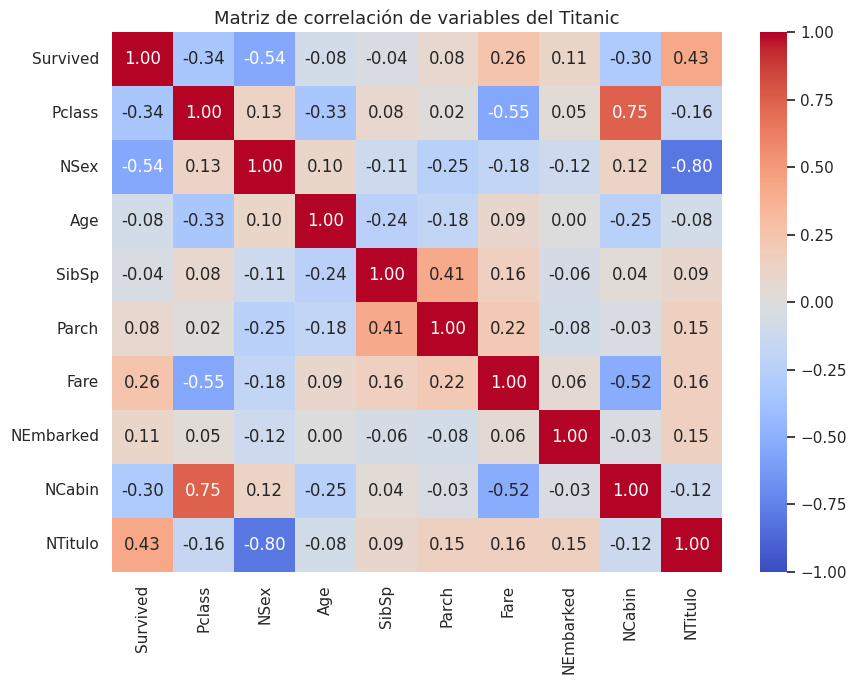

In [221]:
# 3. Dibuja sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, vmin=-1, vmax=1)
#    con plt.figure(figsize=(9, 7)).
plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, vmin=-1, vmax=1)
plt.title('Matriz de correlación de variables del Titanic')
plt.tight_layout()
plt.show()

In [222]:
# 4. Imprime solo la columna de 'Survived' ordenada: corr['Survived'].sort_values()
corr['Survived'].sort_values()

,Survived
NSex,-0.543351
Pclass,-0.338481
NCabin,-0.301116
Age,-0.080453
SibSp,-0.035322
Parch,0.081629
NEmbarked,0.106811
Fare,0.257307
NTitulo,0.428661
Survived,1.000000


### Paso 28. Estadísticas descriptivas por grupos

Genera cuatro tablas con `groupby`:

In [223]:
# 1. Edad según supervivencia:   df.groupby('Survived')['Age'].describe()
df.groupby('Survived')['Age'].describe()

,count,mean,std,min,25%,50%,75%,max
Survived,,,,,,,,
0,549.0,30.562012,12.460355,1.00,23.0,30.726645,35.0,74.0
1,342.0,28.410122,13.774087,0.42,21.0,27.915709,35.0,80.0


In [224]:
# 2. Supervivencia por sexo:     df.groupby('Sex')['Survived'].agg(['mean', 'sum', 'count'])
df.groupby('Sex')['Survived'].agg(['mean', 'sum', 'count'])

,mean,sum,count
Sex,,,
female,0.742038,233,314
male,0.188908,109,577


In [225]:
# 3. Supervivencia por clase:    igual que (2) con 'Pclass'
df.groupby('Pclass')['Survived'].agg(['mean', 'sum', 'count'])

,mean,sum,count
Pclass,,,
1,0.629630,136,216
2,0.472826,87,184
3,0.242363,119,491


In [226]:
# 4. Supervivencia por 'Alone':  igual que (2) con 'Alone'
df.groupby('Alone')['Survived'].agg(['mean', 'sum', 'count'])

,mean,sum,count
Alone,,,
Alone,0.303538,163,537
With Family,0.505650,179,354


### Paso 29. ¿Es la diferencia por sexo estadísticamente significativa? (Chi-cuadrado)

> **Teoría — prueba de independencia chi-cuadrado.** Compara los conteos observados en una tabla cruzada con los que se esperarían **si las dos variables fueran independientes**.
> - **H₀:** `Sex` y `Survived` son independientes (el sexo no se asocia con sobrevivir).
> - **H₁:** sí hay asociación.
>
> Si `p < 0.05` se rechaza H₀. **Un p-valor pequeño no dice que la asociación sea grande ni causal**, solo que es poco probable que sea azar.


In [227]:
# 1. Construye la tabla de contingencia: tabla = pd.crosstab(df['Sex'], df['Survived'])
tabla = pd.crosstab(df['Sex'], df['Survived'])
tabla

Survived,0,1
Sex,,
female,81,233
male,468,109


In [228]:
# 2. Aplica: chi2, p, gl, esperados = stats.chi2_contingency(tabla)
chi2, p, gl, esperado = stats.chi2_contingency(tabla)

In [229]:
# 3. Imprime chi2 y p, y escribe en un comentario tu conclusión.
print(f"Chi2: {chi2:.4f} | p-valor: {p:.4e}")
# Conclusión: como p < 0.05 (de hecho p ≈ 1.2e-58), rechazamos H0;
# existe una asociación estadísticamente significativa entre el sexo y la supervivencia.


Chi2: 260.7170 | p-valor: 1.1974e-58


### Evaluación — Parte 6


- **E6.1 (conceptual).** ¿Qué variables están más correlacionadas con `Survived`? ¿Alguna correlación te sorprende o contradice tus hipótesis iniciales?


**R//** Las variables con mayor correlación lineal absoluta con Survived suelen ser NSex (correlación negativa: ser hombre 1 se asocia con menor supervivencia) y Pclass (correlación negativa: mayor número de clase, es decir, 3.ª clase, se asocia con menor supervivencia), junto con Fare (positiva). Confirma el patrón de "mujeres y clase alta primero", aunque ver qué tan fuerte es el impacto en 3.ª clase o en niños ayuda a matizar la intuición inicial.

- **E6.2 (conceptual).** ¿Qué grupo demográfico tuvo las mejores y las peores tasas de supervivencia, según el Paso 28?


**R//** Según el Paso 28, los grupos con mayor tasa de supervivencia son las mujeres (female), los pasajeros de 1.ª clase y quienes viajaban acompañados (With Family), mientras que las menores tasas corresponden a los hombres (male), los pasajeros de 3.ª clase y quienes viajaban solos (Alone).

- **E6.3 (código).** Repite el Paso 29 con `Pclass` y `Survived`. ¿Qué concluyes? ¿Por qué esta prueba exige variables categóricas?


In [230]:
# Reto E6.3
tabla_pclass = pd.crosstab(df['Pclass'], df['Survived'])
chi2_pc, p_pc, gl_pc, _ = stats.chi2_contingency(tabla_pclass)
print(tabla_pclass)
print(f"Chi2: {chi2_pc:.4f} | p-valor: {p_pc:.4e} | gl: {gl_pc}")

Survived    0    1
Pclass            
1          80  136
2          97   87
3         372  119
Chi2: 102.8890 | p-valor: 4.5493e-23 | gl: 2


- **E6.4 (conceptual).** `NCabin` se correlaciona con `Survived`. ¿Puedes interpretar el **signo** de esa correlación sin recordar cómo la codificaste? ¿Qué te dice eso sobre el uso de códigos numéricos arbitrarios?


**R//** No puedes interpretar el signo de la correlación de NCabin sin recordar cómo se asignaron los números, porque el orden numérico (0, 1, 2...) de las letras de cubierta es arbitrario. Usar códigos numéricos arbitrarios para categorías nominales crea distancias y órdenes ficticios que distorsionan cálculos lineales y modelos.

- **E6.5 (conceptual).** Si `Fare` y `Pclass` están fuertemente correlacionadas (con signo negativo), ¿es un error o es lo esperable? ¿Qué problema generaría usar ambas a la vez en un modelo?


**R//**  No es un error: es esperable porque los boletos de clases superiores (Pclass = 1) costaban mucho más (Fare alta) que los de 3.ª clase (Pclass = 3). Meter ambas variables fuertemente colineales a la vez en un modelo puede generar multicolinealidad, inestabilidad en los coeficientes y dificultad para separar el efecto propio de la tarifa frente al de la clase.


## Parte 7 — Visualizaciones comparativas avanzadas (Pasos 30–31)


### Paso 30. Boxplots múltiples (cuadrícula 2×2)

> **Teoría — boxplot.** La caja va del cuartil 1 al 3 (el 50 % central); la línea interior es la mediana; los "bigotes" llegan hasta 1.5·IQR; los puntos fuera son **candidatos a atípicos**.


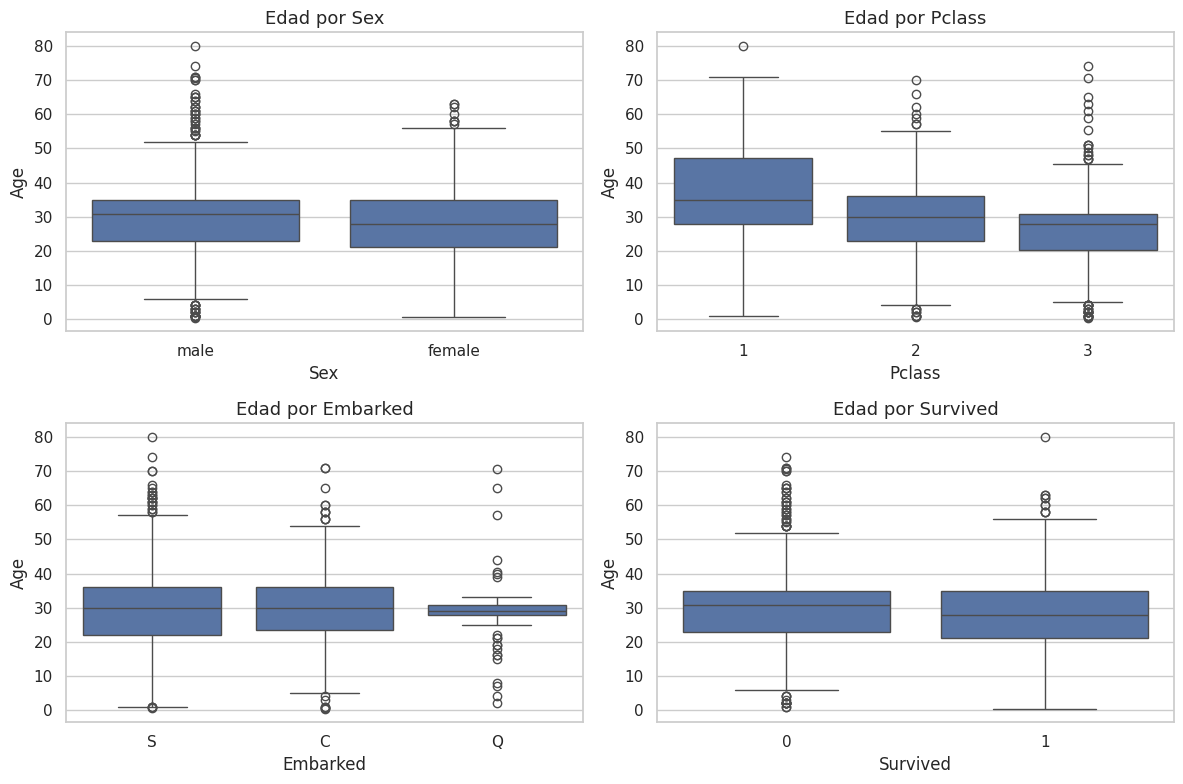

In [231]:
# 1. fig, axes = plt.subplots(2, 2, figsize=(12, 9))
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
# 2. Dibuja sns.boxplot(data=df, x=..., y='Age', ax=axes[f, c]) para:
#      axes[0,0] -> x='Sex'     axes[0,1] -> x='Pclass'
#      axes[1,0] -> x='Embarked' axes[1,1] -> x='Survived'
sns.boxplot(data=df, x='Sex', y='Age', ax=axes[0, 0])
axes[0, 0].set_title('Edad por Sex')

sns.boxplot(data=df, x='Pclass', y='Age', ax=axes[0, 1])
axes[0, 1].set_title('Edad por Pclass')

sns.boxplot(data=df, x='Embarked', y='Age', ax=axes[1, 0])
axes[1, 0].set_title('Edad por Embarked')

sns.boxplot(data=df, x='Survived', y='Age', ax=axes[1, 1])
axes[1, 1].set_title('Edad por Survived')
# 3. Cierra con plt.tight_layout(); plt.show()
plt.tight_layout()
plt.show()

### Paso 31. Distribución de la tarifa


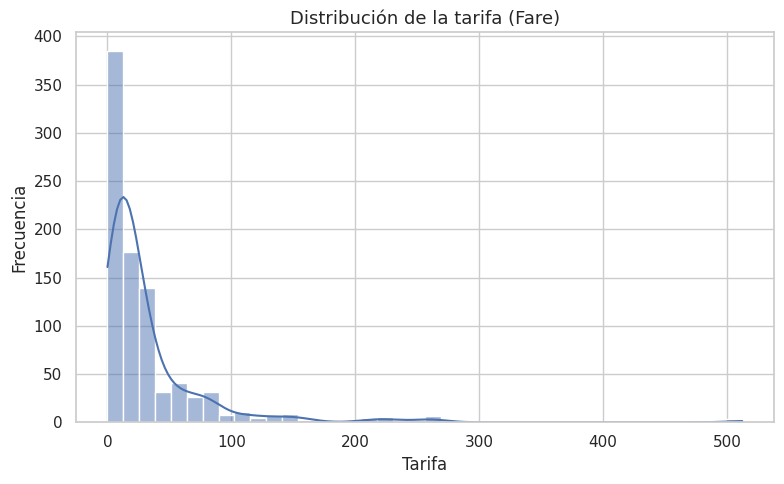

In [232]:
# 1. Histograma con KDE: sns.histplot(df['Fare'], kde=True, bins=40)
sns.histplot(df['Fare'], kde=True, bins=40)
plt.title('Distribución de la tarifa (Fare)')
plt.xlabel('Tarifa')
plt.ylabel('Frecuencia')
plt.tight_layout()
plt.show()

In [233]:
# 2. Calcula media, mediana y asimetría (skew) de 'Fare'.
print("Media:", df['Fare'].mean())
print("Mediana:", df['Fare'].median())
print("Asimetría (skew):", df['Fare'].skew())

Media: 32.204207968574636
Mediana: 14.4542
Asimetría (skew): 4.787316519674893


### Evaluación — Parte 7


- **E7.1 (conceptual).** ¿Qué revelan los boxplots sobre la edad en distintos grupos? Atención: las edades ya están **imputadas**; ¿cómo afecta eso a lo que ves?


**R//** Los boxplots muestran cómo varía la mediana y el rango de edad entre categorías (por ejemplo, edades mayores en 1.ª clase y medianas cercanas entre sobrevivientes y no sobrevivientes). Como las edades faltantes ya fueron imputadas con el promedio por género, hay franjas horizontales concentradas en esos promedios y menor dispersión aparente dentro de cada sexo.

- **E7.2 (conceptual).** ¿La distribución de `Fare` es normal? ¿Qué te dice sobre la composición socioeconómica del barco? ¿Qué medida de tendencia central es más representativa?


**R//** No es normal: tiene un fuerte sesgo positivo (a la derecha), con la mayoría de boletos baratos y unos pocos muy caros. Esto indica una marcada desigualdad socioeconómica a bordo (muchos pasajeros en tarifas bajas y un grupo reducido pagando tarifas muy altas). La mediana es más representativa que la media porque no se ve inflada por los valores extremos.

- **E7.3 (código).** Dibuja el histograma de `np.log1p(df['Fare'])`. ¿Qué cambió y por qué se usa esta transformación?


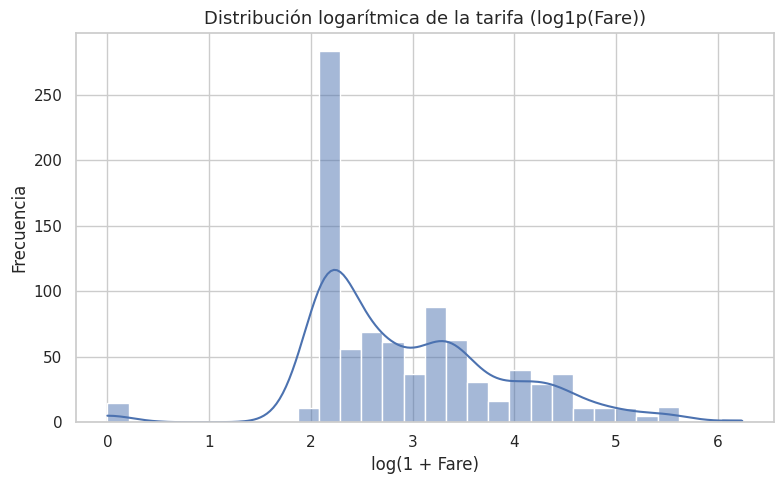

In [234]:
# Reto E7.3
sns.histplot(np.log1p(df['Fare']), kde=True, bins=30)
plt.title('Distribución logarítmica de la tarifa (log1p(Fare))')
plt.xlabel('log(1 + Fare)')
plt.ylabel('Frecuencia')
plt.tight_layout()
plt.show()

## Parte 8 — Preparación del dataset final (Pasos 32–33)


### Paso 32. Limpieza final

**Lógica:** ya creamos versiones numéricas o derivadas de `Name`, `Sex`, `Embarked` y `Cabin`. Las originales se eliminan **en una copia**, de modo que `df` conserve todo para el análisis crítico de la Parte 9.



In [235]:
# df_final = df.drop(columns=[...]) con las 4 columnas originales a eliminar.
df_final = df.drop(columns=['Name', 'Sex', 'Embarked', 'Cabin'])

### Paso 33. Verificación


In [236]:
# 1. Confirma que no quedan nulos en las variables clave (isnull().sum()).
df_final.isnull().sum()

,0
PassengerId,0
Survived,0
Pclass,0
Age,0
SibSp,0
Parch,0
Ticket,0
Fare,0
Person,0
Familia,0


In [237]:
# 2. Revisa los tipos de datos (dtypes) e info().
print(df_final.dtypes)
df_final.info()

PassengerId      int64
Survived         int64
Pclass           int64
Age            float64
SibSp            int64
Parch            int64
Ticket          object
Fare           float64
Person          object
Familia          int64
Alone           object
Survivor        object
NEmbarked        int64
NSex             int64
TCabin          object
NCabin           int64
Titulo          object
NTitulo          int64
dtype: object
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 18 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Age          891 non-null    float64
 4   SibSp        891 non-null    int64  
 5   Parch        891 non-null    int64  
 6   Ticket       891 non-null    object 
 7   Fare         891 non-null    float64
 8   Person       891 non-null    object 
 9   

In [238]:
# 3. Genera un resumen final con describe().
df_final.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare,Familia,NEmbarked,NSex,NCabin,NTitulo
count,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.736034,0.523008,0.381594,32.204208,0.904602,0.361392,0.647587,6.716049,0.630752
std,257.353842,0.486592,0.836071,13.014897,1.102743,0.806057,49.693429,1.613459,0.635673,0.477990,2.460739,0.890346
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,22.000000,0.000000,0.000000,7.910400,0.000000,0.000000,0.000000,8.000000,0.000000
50%,446.000000,0.000000,3.000000,30.000000,0.000000,0.000000,14.454200,0.000000,0.000000,1.000000,8.000000,0.000000
75%,668.500000,1.000000,3.000000,35.000000,1.000000,0.000000,31.000000,1.000000,1.000000,1.000000,8.000000,1.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200,10.000000,2.000000,1.000000,8.000000,3.000000


### Evaluación — Parte 8


- **E8.1 (conceptual).** ¿Qué columnas de texto siguen presentes en `df_final`? ¿Podría un modelo de Scikit-Learn usarlas tal cual?


**R//** Quedan columnas de texto o categóricas como Ticket, Survivor, Alone y Titulo (según las columnas conservadas). Un modelo de scikit-learn no puede usar columnas de texto crudo directamente sin codificarlas o descartarlas, ya que espera entradas numéricas.

- **E8.2 (código).** Convierte `Alone` en una columna numérica `NAlone` (0 = con familia, 1 = solo) y `Person` en `NPerson` (child = 0, female = 1, male = 2).


In [239]:
# Reto E8.2
df_final['NAlone'] = np.where(df_final['Alone'] == 'Alone', 1, 0)
df_final['NPerson'] = df_final['Person'].map({'child': 0, 'female': 1, 'male': 2})
df_final[['Alone', 'NAlone', 'Person', 'NPerson']].head(10)

,Alone,NAlone,Person,NPerson
0,With Family,0,male,2
1,With Family,0,female,1
2,Alone,1,female,1
3,With Family,0,female,1
4,Alone,1,male,2
5,Alone,1,male,2
6,Alone,1,male,2
7,With Family,0,child,0
8,With Family,0,female,1
9,With Family,0,child,0


- **E8.3 (conceptual).** ¿Tiene sentido conservar `PassengerId` y `Ticket` para predecir supervivencia? Justifica.


**R//** No tiene sentido usar PassengerId (es solo un identificador secuencial asignado en la tabla, sin relación causal con sobrevivir). En cambio, Titulo sí puede aportar información útil porque resume estatus social, edad y género/estado civil, aunque conviene codificarlo adecuadamente (por ejemplo, con codificación one-hot) y evitar fuga de datos.

## Parte 9 — Análisis crítico: interacciones, asociaciones y atípicos (Pasos 34–38)

Esta es la parte donde pasas de **describir** a **argumentar**. Aquí un número solo no basta: hay que preguntarse si es *grande*, si es *confiable* (¿cuántos pasajeros hay detrás?) y si es *justo* compararlo (¿hay una tercera variable que confunde?).

> **Teoría — variable de confusión.** Si el puerto parece influir en la supervivencia, quizá lo que influye es la **clase** (cada puerto trae pasajeros de clases distintas). Para separar efectos se **estratifica**: se compara dentro de cada nivel de la tercera variable.



### Paso 34. Interacciones: clase × género


In [240]:
# Tabla de tasa de supervivencia con Pclass en filas y Sex en columnas:
# df.pivot_table(values='Survived', index='Pclass', columns='Sex', aggfunc='mean')
df.pivot_table(values='Survived', index='Pclass', columns='Sex', aggfunc='mean')

Sex,female,male
Pclass,,
1,0.968085,0.368852
2,0.921053,0.157407
3,0.500000,0.135447


### Paso 35. Puerto de embarque y supervivencia (¿con confusión?)


In [241]:
# 1. Tasa de supervivencia y número de pasajeros por 'Embarked' (groupby + agg ['mean', 'count']).
df.pivot_table(values='Survived', index='Pclass', columns='Sex', aggfunc='mean')

Sex,female,male
Pclass,,
1,0.968085,0.368852
2,0.921053,0.157407
3,0.500000,0.135447


In [242]:
# 2. Repite estratificando por clase: pivot_table con index='Embarked', columns='Pclass'.
df.pivot_table(values='Survived', index='Embarked', columns='Pclass', aggfunc='mean')

Pclass,1,2,3
Embarked,,,
C,0.694118,0.529412,0.378788
Q,0.500000,0.666667,0.375000
S,0.589147,0.463415,0.189802


### Paso 36. Tarifa y supervivencia dentro de cada clase

**Lógica:** para ver si pagar más ayudaba **dentro de una misma clase**, dividimos la tarifa en cuartiles *por clase* con `pd.qcut` y comparamos tasas.


In [243]:
# 1. Crea df['FareQ'] con cuartiles de Fare calculados dentro de cada Pclass:
#    df['FareQ'] = df.groupby('Pclass')['Fare'].transform(lambda s: pd.qcut(s, 4, labels=False, duplicates='drop'))
df['FareQ'] = df.groupby('Pclass')['Fare'].transform(
    lambda s: pd.qcut(s, 4, labels=False, duplicates='drop')
)
df.pivot_table(values='Survived', index='Pclass', columns='FareQ', aggfunc='mean')

FareQ,0,1,2,3
Pclass,,,,
1,0.462963,0.574074,0.745455,0.735849
2,0.345238,0.500000,0.584906,0.589744
3,0.226562,0.200000,0.275510,0.283333


In [244]:
# 2. pivot_table: tasa de 'Survived' con index='FareQ' y columns='Pclass'.
df.pivot_table(values='Survived', index='FareQ', columns='Pclass', aggfunc='mean')

Pclass,1,2,3
FareQ,,,
0,0.462963,0.345238,0.226562
1,0.574074,0.500000,0.200000
2,0.745455,0.584906,0.275510
3,0.735849,0.589744,0.283333


### Paso 37. Tamaño de la familia


In [245]:
# 1. Tasa de supervivencia y cantidad de pasajeros por 'Familia' (groupby + agg).
df.groupby('Familia')['Survived'].agg(['mean', 'count'])

,mean,count
Familia,,
0,0.303538,537
1,0.552795,161
2,0.578431,102
3,0.724138,29
4,0.200000,15
5,0.136364,22
6,0.333333,12
7,0.000000,6
10,0.000000,7


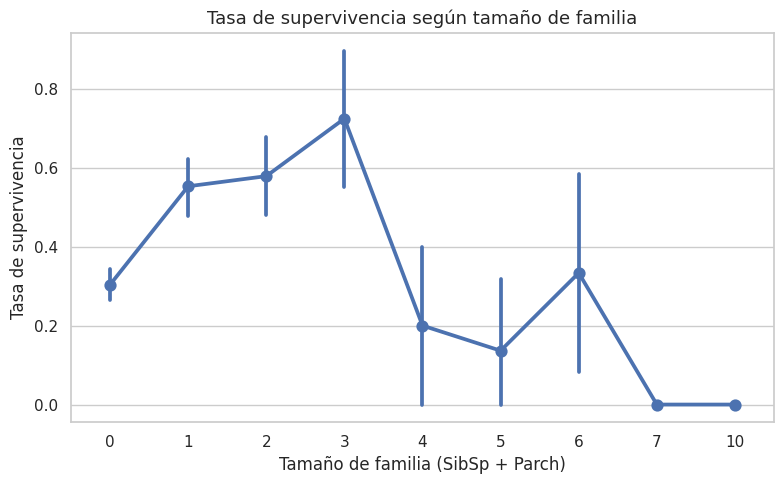

In [246]:
sns.pointplot(data=df, x='Familia', y='Survived')
plt.title('Tasa de supervivencia según tamaño de familia')
plt.xlabel('Tamaño de familia (SibSp + Parch)')
plt.ylabel('Tasa de supervivencia')
plt.tight_layout()
plt.show()

### Paso 38. Pasajeros atípicos

> **Teoría — regla IQR.** `IQR = Q3 − Q1`. Es atípico lo que queda fuera de `[Q1 − 1.5·IQR, Q3 + 1.5·IQR]`. *Atípico no significa erróneo:* antes de eliminar, pregunta si es un error de captura o un caso real.



In [247]:
# 1. Escribe una función outliers_iqr(serie) que devuelva una máscara booleana
#    (usa serie.quantile([0.25, 0.75])).
def outlier_iqr(serie):
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    lim_inf = q1 - 1.5 * iqr
    lim_sup = q3 + 1.5 * iqr
    return (serie < lim_inf) | (serie > lim_sup)

In [248]:
# 2. Aplícala a 'Fare', 'Age' y 'Familia' y cuenta cuántos atípicos hay en cada una.
for col in ['Fare', 'Age', 'Familia']:
    mask = outlier_iqr(df[col].dropna())
    print(f"Atípicos IQR en {col}: {mask.sum()}")

Atípicos IQR en Fare: 116
Atípicos IQR en Age: 66
Atípicos IQR en Familia: 91


In [249]:
# 3. Compara la tasa de supervivencia de los atípicos de 'Fare' contra el resto.
mask_fare = outlier_iqr(df['Fare'])
df.groupby(mask_fare)['Survived'].agg(['mean', 'count'])

,mean,count
Fare,,
False,0.339355,775
True,0.681034,116


In [250]:
# 4. Muestra los pasajeros con la tarifa más alta (nlargest).
df.nlargest(10, 'Fare')[['Name', 'Pclass', 'Age', 'Fare', 'Survived']]

,Name,Pclass,Age,Fare,Survived
258,"Ward, Miss. Anna",1,35.0,512.3292,1
679,"Cardeza, Mr. Thomas Drake Martinez",1,36.0,512.3292,1
737,"Lesurer, Mr. Gustave J",1,35.0,512.3292,1
27,"Fortune, Mr. Charles Alexander",1,19.0,263.0000,0
88,"Fortune, Miss. Mabel Helen",1,23.0,263.0000,1
341,"Fortune, Miss. Alice Elizabeth",1,24.0,263.0000,1
438,"Fortune, Mr. Mark",1,64.0,263.0000,0
311,"Ryerson, Miss. Emily Borie",1,18.0,262.3750,1
742,"Ryerson, Miss. Susan Parker ""Suzette""",1,21.0,262.3750,1
118,"Baxter, Mr. Quigg Edmond",1,24.0,247.5208,0


### Evaluación — Parte 9


- **E9.1 (conceptual).** ¿Era ser mujer de tercera clase muy diferente de ser mujer de primera clase? Cuantifica la diferencia con tu tabla del Paso 34.


**R//** Sí, era muy diferente: según la tabla del Paso 34, las mujeres de 1.ª clase tuvieron una tasa de supervivencia muy alta (~97 %), mientras que las de 3.ª clase tuvieron cerca del 50 %, evidenciando una brecha cercana a 47 puntos porcentuales por clase social.   

- **E9.2 (conceptual).** ¿Los puertos tienen tasas de supervivencia distintas? Tras estratificar por clase, ¿esa diferencia se mantiene? ¿Qué es entonces el puerto: causa o proxy?


**R//** En bruto los puertos muestran tasas distintas (C más alta, Q y S más bajas), pero al estratificar por Pclass las diferencias entre puertos se reducen o cambian. El puerto actúa principalmente como proxy (variable asociada) de la composición de clases y tarifas de quienes embarcaban allí, más que como causa directa de sobrevivir.   

- **E9.3 (conceptual).** ¿Existe una relación no lineal entre tarifa y supervivencia dentro de cada clase? ¿Qué cuidado hay con el tamaño de cada celda?


**R//** Dentro de cada clase (FareQ en el Paso 36) la relación entre tarifa y supervivencia no es estrictamente lineal ni uniforme en todos los cuartiles, y hay que cuidar el tamaño de cada celda porque dividir en cuartiles por clase reduce el número de pasajeros por grupo y aumenta la variabilidad muestral.   

- **E9.4 (conceptual).** ¿Hay un número "óptimo" de familiares? ¿Viajar con muchos fue contraproducente? ¿Cuántos pasajeros respaldan los extremos?


**R//** Parece haber un tamaño intermedio favorable (familias pequeñas, de 1 a 3 familiares) frente a viajar solo o en familias muy grandes (4 o más), donde viajar con muchos pudo ser contraproducente por dificultad para coordinarse y abordar juntos; los extremos de mayor tamaño tienen pocos pasajeros, por lo que su estimación es más ruidosa.   

- **E9.5 (código).** Verifica tu hipótesis de E3.5 con una **prueba chi-cuadrado** entre `Alone` y `Survived`. ¿Qué advertencia harías antes de concluir que "viajar con familia ayuda"? (Pista: ¿la gente sola es distinta en edad, sexo o clase?)


In [251]:
# Retos E9.5
tabla_alone = pd.crosstab(df['Alone'], df['Survived'])
chi2_a, p_a, gl_a, _ = stats.chi2_contingency(tabla_alone)
print(tabla_alone)
print(f"Chi2: {chi2_a:.4f} | p-valor: {p_a:.4e} | gl: {gl_a}")

Survived       0    1
Alone                
Alone        374  163
With Family  175  179
Chi2: 36.0005 | p-valor: 1.9727e-09 | gl: 1


- **E9.6 (conceptual).** ¿Es correcto eliminar automáticamente a los outliers de `Fare`? Da un argumento a favor y uno en contra, citando cómo les fue a esos pasajeros.


**R//** No conviene eliminarlos automáticamente. A favor: evita que tarifas extremas distorsionen promedios o regresiones lineales. En contra: los pasajeros con Fare atípica corresponden en su mayoría a 1.ª clase con alta supervivencia, por lo que eliminarlos borraría un subgrupo clave para entender cómo el estatus y el costo del boleto se asocian con sobrevivir.   

## Conclusión y reporte

Responde, **con evidencia de tu análisis** (indica el **Paso** del que proviene cada afirmación) y en un máximo de **8 líneas en total**, sin código:


1. ¿Cuál fue el factor más determinante para la supervivencia?


**R//** El sexo/condición de persona y la clase social fueron los factores más determinantes, con mayor supervivencia en mujeres y 1.ª clase y muy baja en hombres adultos de 3.ª clase (Pasos 17, 18, 27, 28, 29 y 34).



2. ¿Se confirma "mujeres y niños primero"? ¿Con qué excepciones?


**R//** Se confirma en términos generales en 1.ª y 2.ª clase, pero tiene excepciones importantes en 3.ª clase, donde mujeres y niños tuvieron tasas mucho menores que en clases altas (Pasos 18 y E4.2).

3. ¿Cómo influyó la clase social?


**R//** Viajar en familia pequeña tendió a asociarse con mayor supervivencia que viajar solo, mientras que familias muy grandes mostraron caídas por mayor dificultad de evacuación conjunta, sujeto a confusión por edad y clase (Pasos 14, 28, 37 y E9.5).

4. ¿Viajar con familia ayudó o perjudicó?


**R//** Viajar en familia pequeña tendió a asociarse con mayor supervivencia que viajar solo, mientras que familias muy grandes mostraron caídas por mayor dificultad de evacuación conjunta, sujeto a confusión por edad y clase (Pasos 14, 28, 37 y E9.5).

5. ¿Qué factores inesperados descubriste?


**R//**  Resultó inesperado que la regla de "mujeres y niños primero" fallara marcadamente en 3.ª clase, que el puerto de embarque pareciera influir solo por actuar como proxy de clase/tarifa, que viajar en familias muy grandes redujera la supervivencia frente a familias pequeñas y que los valores nulos de Age sesgaran Person hacia adulto/sexo (Pasos 8, 18, 35, 37, E2.5, E4.2 y E9.2).   

Después, en un párrafo corto de **limitaciones**, reflexiona sobre:


- ¿Qué datos faltantes pudieron sesgar tus conclusiones (edad, cabina)?


**R//** Los faltantes en Age y el alto porcentaje de nulos en Cabin pudieron sesgar estimaciones por edad o cubierta y subestimar niños (child) cuando faltaba la edad (Pasos 5, 8, 11, 22, 24, E2.5 y E3.2).

- ¿Qué variables adicionales hubieras querido tener (ubicación en el barco, tiempo de acceso a botes salvavidas, nacionalidad, tripulación)?


**R//** Hubiera sido valioso contar con ubicación exacta en el barco/camarote, tiempos y rutas reales de acceso a botes salvavidas, nacionalidad y rol como tripulación o pasajero para aislar causas operativas.

- ¿Qué supuestos hiciste que podrían ser cuestionables (promedio por género, `Master → Mr`, códigos numéricos arbitrarios, tratar la muestra como "todo el barco")?


**R//** Imputar Age con promedios por sexo, consolidar títulos como Master -> Mr, usar códigos numéricos arbitrarios para categorías y tratar la muestra de 891 pasajeros como "todo el barco" son supuestos que reducen variabilidad, imponen órdenes artificiales o limitan generalizar a todos los viajeros del Titanic.